In [12]:
from pathlib import Path
import pandas as pd
import json
import pickle
import warnings
import shutil
import re, glob
import hdf5storage
from tqdm import tqdm
from copy import deepcopy
import numpy as np
import h5py

import importlib
# import utils.functions as func
# importlib.reload(func)
# from utils.functions import *
# import utils.pre_processing as pre_processing
# importlib.reload(pre_processing)
# from utils.pre_processing import symmetric_intensities #, radial_profile, radial_profile_2d, radial_profile_2d_masked



import tifffile
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from scipy.ndimage import map_coordinates
import matplotlib as mpl
from matplotlib.patches import Circle
from matplotlib.colors import Normalize
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.legend import Legend
from matplotlib.legend_handler import HandlerTuple
from photutils.aperture import RectangularAnnulus
from photutils.detection import find_peaks
plt.close('all')

# from hcipy import Field, make_pupil_grid, get_strehl_from_focal, radial_profile
from applefy_extensions.contrast_curves import ContrastFast
from applefy.statistics import TTest, gaussian_sigma_2_fpf, fpf_2_gaussian_sigma
from applefy.utils.file_handling import load_adi_data
from applefy.utils import flux_ratio2mag, mag2flux_ratio
from applefy.utils.photometry import AperturePhotometryMode
from applefy.utils.file_handling import save_as_fits
from applefy.utils.contrast_grid import compute_contrast_from_grid
from applefy.utils.positions import center_subpixel



from fours.utils.data_handling import read_fours_root_dir
from fours.utils.setups import contrast_grid_setup_1
from fours.detection_limits.applefy_wrapper import CADIDataReductionGPU, PCADataReductionGPU
from fours.detection_limits.applefy_wrapper import FourSDataReduction
from fours.models.psf_subtraction import FourS


from pipeline_pre_ADI.pre_process.plot_pre_processing import *
from pipeline_pre_ADI.pre_process.pre_processing import *
from pipeline_pre_ADI.pre_process.correlation import *
from utils.naming import *

# Saved best Contrast Curve

In [2]:
#raw_contrast_dic = pd.HDFStore(f"/home/aosimul/noah/data/ghost_images/10_15_20ws/raw_contrast.h5",'r')
all_best = pd.HDFStore(f"/home/aosimul/noah/src/pipeline_ADI/results/contrast/30_deg_sat_speckles/overall_best.h5",'r')
all_best.info()
all_best.keys()

['/int_7ro_20ws_1key_1-4_DIT_1.41e+00s',
 '/int_7ro_20ws_1key_1-4_DIT_1.41e-02s',
 '/int_7ro_20ws_1key_1-4_DIT_2.81e+00s',
 '/int_7ro_20ws_1key_1-4_DIT_2.81e-01s',
 '/int_7ro_20ws_1key_1-4_DIT_2.81e-02s',
 '/int_7ro_20ws_1key_1-4_DIT_8.44e-03s',
 '/pred_7ro_20ws_1key_1-4_DIT_1.41e+00s',
 '/pred_7ro_20ws_1key_1-4_DIT_1.41e-02s',
 '/pred_7ro_20ws_1key_1-4_DIT_2.81e+00s',
 '/pred_7ro_20ws_1key_1-4_DIT_2.81e-01s',
 '/pred_7ro_20ws_1key_1-4_DIT_2.81e-02s',
 '/pred_7ro_20ws_1key_1-4_DIT_8.44e-03s']

In [33]:

def truncate_cmap(name, lo=0.3, hi=1.0, n=256):
    """Cut off the near-white end of a sequential colormap so all curves stay visible."""
    base = plt.get_cmap(name)
    return LinearSegmentedColormap.from_list(f"{name}_trunc", base(np.linspace(lo, hi, n)))


def get_dit_keys(all_best, algo, name):
    """Return [(dit_value, key), ...] sorted by DIT, for keys like '/pred_<name>_DIT_1.407s'."""
    pat = re.compile(rf"^/{algo}_{re.escape(name)}_DIT_([0-9.eE+-]+)s$")
    out = []
    for k in all_best:
        m = pat.match(k)
        if m:
            out.append((float(m.group(1)), k))
    return sorted(out)


def plot_dit_comparison(all_best, name="7ro_20ws_1key_1-4", algos=("int", "pred"),
                        titling=lambda s: s, band_alpha=0.15, ylim=(4e-6, 1e-2),
                        use_log_dit=True, savepath=None):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharey=True)

    # DIT range over both algos so colours are comparable between the panels
    all_dits = [d for a in algos for d, _ in get_dit_keys(all_best, a, name)]
    if not all_dits:
        raise ValueError("No DIT keys found - check `name`.")
    NormCls = LogNorm if use_log_dit else mpl.colors.Normalize
    norm = NormCls(vmin=min(all_dits), vmax=max(all_dits))
    cm_cadi, cm_pca = truncate_cmap("Reds"), truncate_cmap("Blues")

    def band(ax, x, y, s, color, alpha):
        lo = np.clip(y - s, 1e-22, None)  # keep positive for the log axis
        ax.fill_between(x, y - s, y + s, color=color, alpha=alpha, lw=0)

    for ax, algo in zip(axes, algos):
        dit_keys = get_dit_keys(all_best, algo, name)

        # raw contrast is independent of DIT -> draw once (from the longest DIT)
        df_ref = all_best[dit_keys[-1][1]]
        x_rc = df_ref["raw_contrast"].index.get_level_values("pixel_rad")
        ax.plot(x_rc, df_ref["raw_contrast"], color="black", lw=2, label="Raw contrast", zorder=5)
        band(ax, x_rc, df_ref["raw_contrast"].values, df_ref["raw_contrast_std"].values,
             "black", 0.15)

        for dit, key in dit_keys:
            df = all_best[key]
            x = df["best_contrast"].index.get_level_values("pixel_rad")
            c_cadi, c_pca = cm_cadi(norm(dit)), cm_pca(norm(dit))
            
            ax.plot(x, df["cADI_contrast"], color=c_cadi, lw=1.5)
            band(ax, x, df["cADI_contrast"].values, df["cADI_contrast_std"].values, c_cadi, band_alpha)
            ax.plot(x, df["best_contrast"], color=c_pca, lw=1.5)
            band(ax, x, df["best_contrast"].values, df["best_contrast_std"].values, c_pca, band_alpha)

        ax.set_yscale("log")
        ax.grid(which="both", alpha=0.4)
        ax.set_xlabel(r"Separation [FWHM]", size=16)
        ax.set_xlim(x.min(), x.max())
        ax.tick_params(axis="both", which="major", labelsize=13)
        if ylim:
            ax.set_ylim(*ylim)
        ax.set_title(titling(algo), size=16)

    axes[0].set_ylabel(r"Planet-to-star flux ratio", size=16)
    axes[0].legend(fontsize=14, loc="lower right")

    # two colourbars, one per algorithm family (CADI red, PCA blue)
    cb1 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cm_cadi), ax=axes, pad=0.01, aspect=30)
    cb1.set_label("DIT [s] - CADI", size=14)
    cb2 = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cm_pca), ax=axes, pad=0.02, aspect=30)
    cb2.set_label("DIT [s] - Best PCAD", size=14)
    cb1.ax.tick_params(labelsize=13)
    cb2.ax.tick_params(labelsize=13)
    fig.suptitle(r"$5 \sigma_{\mathcal{N}}$ Contrast Curves vs DIT" + f"\nAtmospheric Conditions: {titling(name[:-4])}",
                 size=18)
    if savepath:
        fig.savefig(savepath, dpi=200)
    return fig, axes


# usage:
# fig, axes = plot_dit_comparison(all_best, name="7ro_20ws_1key_1-4", titling=titling)

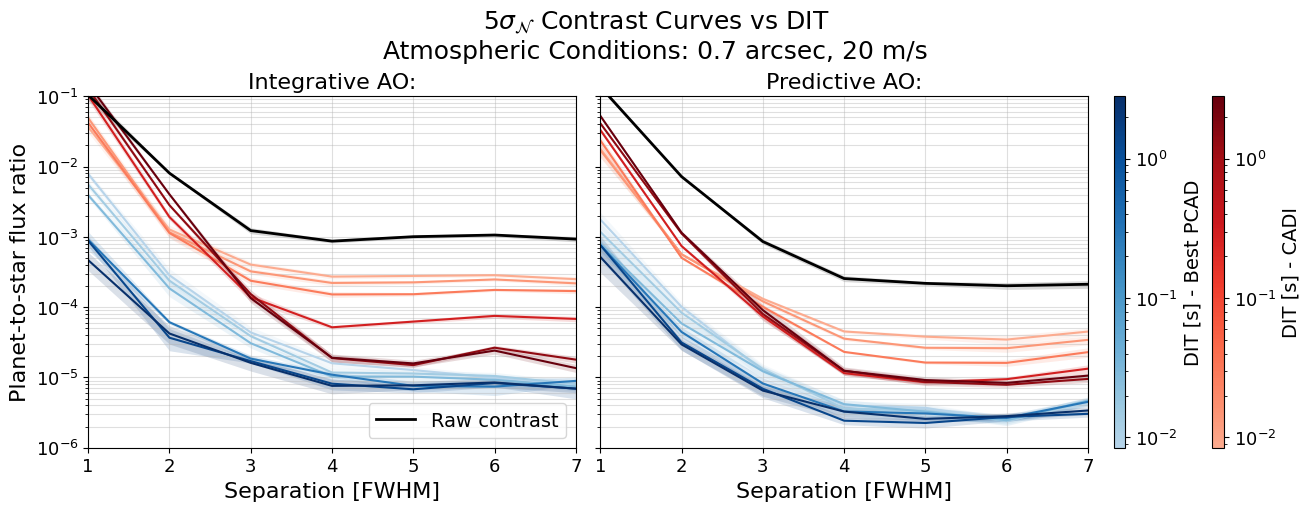

In [34]:
fig, axes = plot_dit_comparison(all_best, name="7ro_20ws_1key_1-4", ylim=(1e-6, 1e-1), titling=titling)

In [9]:
#asuming they all have the same index I average the results of the 3 batches
avr_best = {}
count  = [2]
for ro in [0.5, 0.7, 1.0]:
    for ws in [10, 15,20]:
        for algo in ['int', 'pred']:
            #name = f'coro_{ro*10:.0f}r0_{ws}windspeed'
            name = f'{algo}_{ro*10:.0f}ro_{ws}ws'

            best_contrast = np.mean([
                all_best[f'/{name}_{c}']['best_contrast']
                for c in count
            ], axis = 0)

            best_contrast_std = np.sqrt(np.sum([
                all_best[f'/{name}_{c}']['best_contrast_std']**2
                for c in count
            ], axis=0))

            cADI_contrast = np.mean([
                all_best[f'/{name}_{c}']['cADI_contrast']
                for c in count
            ], axis = 0)

            cADI_contrast_std = np.sqrt(np.sum([
                all_best[f'/{name}_{c}']['cADI_contrast_std']**2
                for c in count
            ], axis=0))

            raw_contrast = np.mean([
                all_best[f'/{name}_{c}']['raw_contrast']
                for c in count
            ], axis = 0)

            raw_contrast_std = np.sqrt(np.sum([
                all_best[f'/{name}_{c}']['raw_contrast_std']**2
                for c in count
            ], axis=0))

            # All counts have the same index, so take it from the first one
            index = all_best[f'/{name}_{count[0]}'].index
            #indew_rw = raw_contrast_dic[f'/{name}_{count[0]}'].index

            avr_best[name] = {
                'best_contrast': pd.Series(best_contrast, index=index),
                'best_contrast_std': pd.Series(best_contrast_std, index=index),
                'cADI_contrast': pd.Series(cADI_contrast, index=index),
                'cADI_contrast_std': pd.Series(cADI_contrast_std, index=index),
                'raw_contrast': pd.Series(raw_contrast, index=index),
                'raw_contrast_std': pd.Series(raw_contrast_std, index=index),
            }
avr_best

{'int_5ro_10ws': {'best_contrast': pixel_rad  pixel_rad_fwhm
  1.0        0.206989          0.000633
  2.0        0.413977          0.000066
  3.0        0.620966          0.000013
  4.0        0.827955          0.000007
  5.0        1.034943          0.000004
  6.0        1.241932          0.000005
  7.0        1.448921          0.000005
  8.0        1.655909          0.000008
  9.0        1.862898          0.000007
  10.0       2.069887          0.000008
  11.0       2.276876          0.000011
  dtype: float64,
  'best_contrast_std': pixel_rad  pixel_rad_fwhm
  1.0        0.206989          7.737864e-05
  2.0        0.413977          1.135230e-05
  3.0        0.620966          2.375169e-06
  4.0        0.827955          5.033062e-07
  5.0        1.034943          4.350954e-07
  6.0        1.241932          8.870814e-06
  7.0        1.448921          6.575302e-07
  8.0        1.655909          8.916972e-07
  9.0        1.862898          7.196477e-06
  10.0       2.069887          1.047

In [8]:
#raw contrast from measuremetn
# #asuming they all have the same index I average the results of the 3 batches
avr_best = {}
count  = [2]
for ro in [ 1.0]:
    for ws in [10, 15, 20]:
        for algo in ['int', 'pred']:
            #name = f'coro_{ro*10:.0f}r0_{ws}windspeed'
            name = f'{algo}_{ro*10:.0f}ro_{ws}ws'

            best_contrast = np.mean([
                all_best[f'/{name}_{c}']['best_contrast']
                for c in count
            ], axis = 0)

            best_contrast_std = np.sqrt(np.sum([
                all_best[f'/{name}_{c}']['best_contrast_std']**2
                for c in count
            ], axis=0))

            cADI_contrast = np.mean([
                all_best[f'/{name}_{c}']['cADI_contrast']
                for c in count
            ], axis = 0)

            cADI_contrast_std = np.sqrt(np.sum([
                all_best[f'/{name}_{c}']['cADI_contrast_std']**2
                for c in count
            ], axis=0))

            raw_contrast = np.mean([
                raw_contrast_dic[f'/{name}_{c}']['raw_contrast']
                for c in count
            ], axis = 0)

            raw_contrast_std = np.std([
                raw_contrast_dic[f'/{name}_{c}']['raw_contrast']
                for c in count
            ], axis = 0)

            # All counts have the same index, so take it from the first one
            index = all_best[f'/{name}_{count[0]}'].index
            indew_rw = raw_contrast_dic[f'/{name}_{count[0]}'].index

            avr_best[name] = {
                'best_contrast': pd.Series(best_contrast, index=index),
                'best_contrast_std': pd.Series(best_contrast_std, index=index),
                'cADI_contrast': pd.Series(cADI_contrast, index=index),
                'cADI_contrast_std': pd.Series(cADI_contrast_std, index=index),
                'raw_contrast': pd.Series(raw_contrast, index=indew_rw),
                'raw_contrast_std': pd.Series(raw_contrast_std, index=indew_rw),
            }
avr_best

{'int_10ro_10ws': {'best_contrast': pixel_rad  pixel_rad_fwhm
  1.0        0.209177          0.005379
  2.0        0.418355          0.000702
  3.0        0.627532          0.000170
  4.0        0.836710          0.000087
  5.0        1.045887          0.000073
  6.0        1.255065          0.000061
  7.0        1.464242          0.000076
  8.0        1.673420          0.000099
  9.0        1.882597          0.000084
  10.0       2.091775          0.000090
  11.0       2.300952          0.000110
  dtype: float64,
  'best_contrast_std': pixel_rad  pixel_rad_fwhm
  1.0        0.209177          0.002137
  2.0        0.418355          0.000256
  3.0        0.627532          0.000031
  4.0        0.836710          0.000016
  5.0        1.045887          0.000014
  6.0        1.255065          0.000014
  7.0        1.464242          0.000022
  8.0        1.673420          0.000010
  9.0        1.882597          0.000026
  10.0       2.091775          0.000030
  11.0       2.300952          

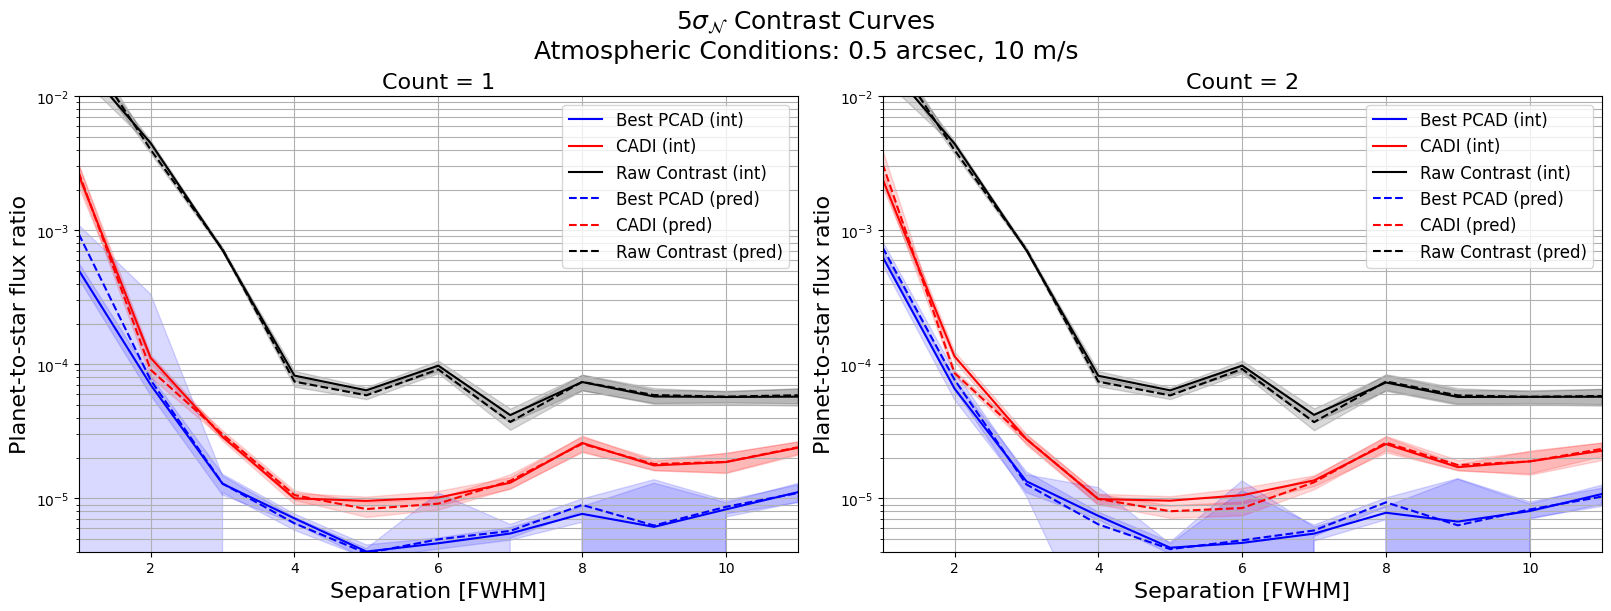

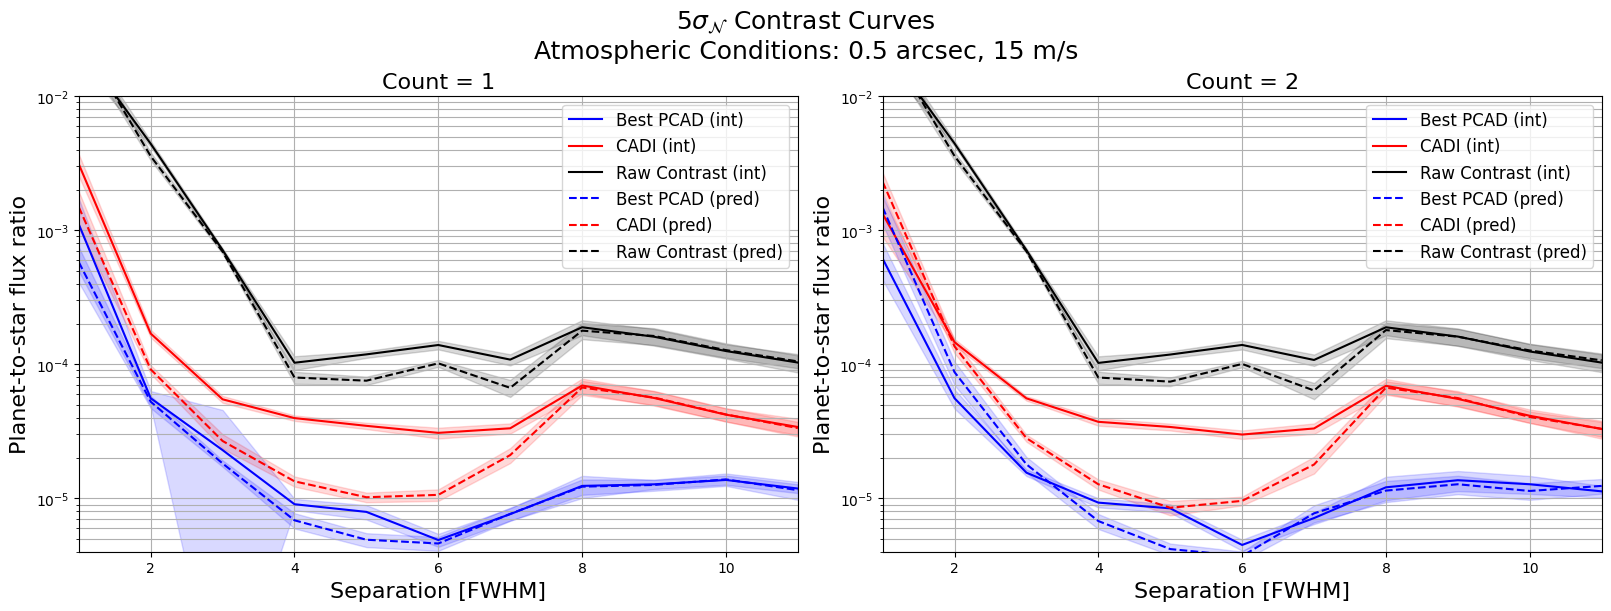

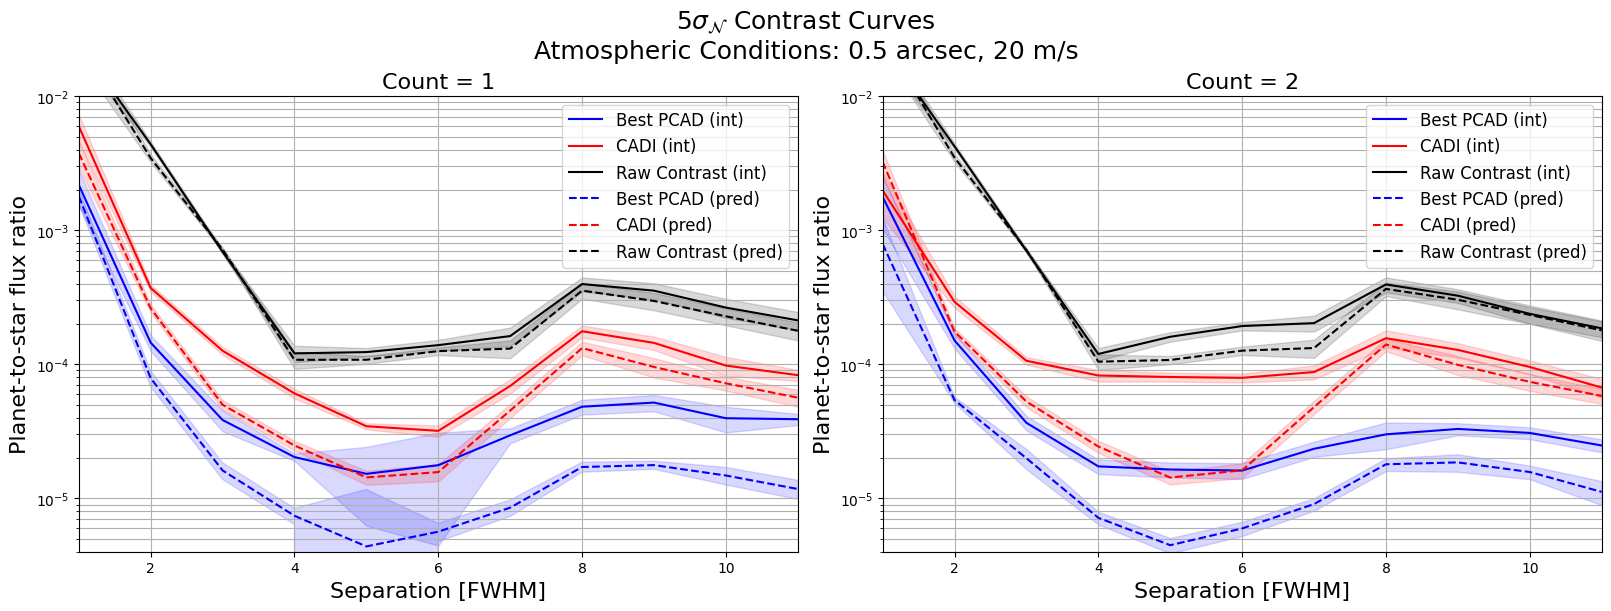

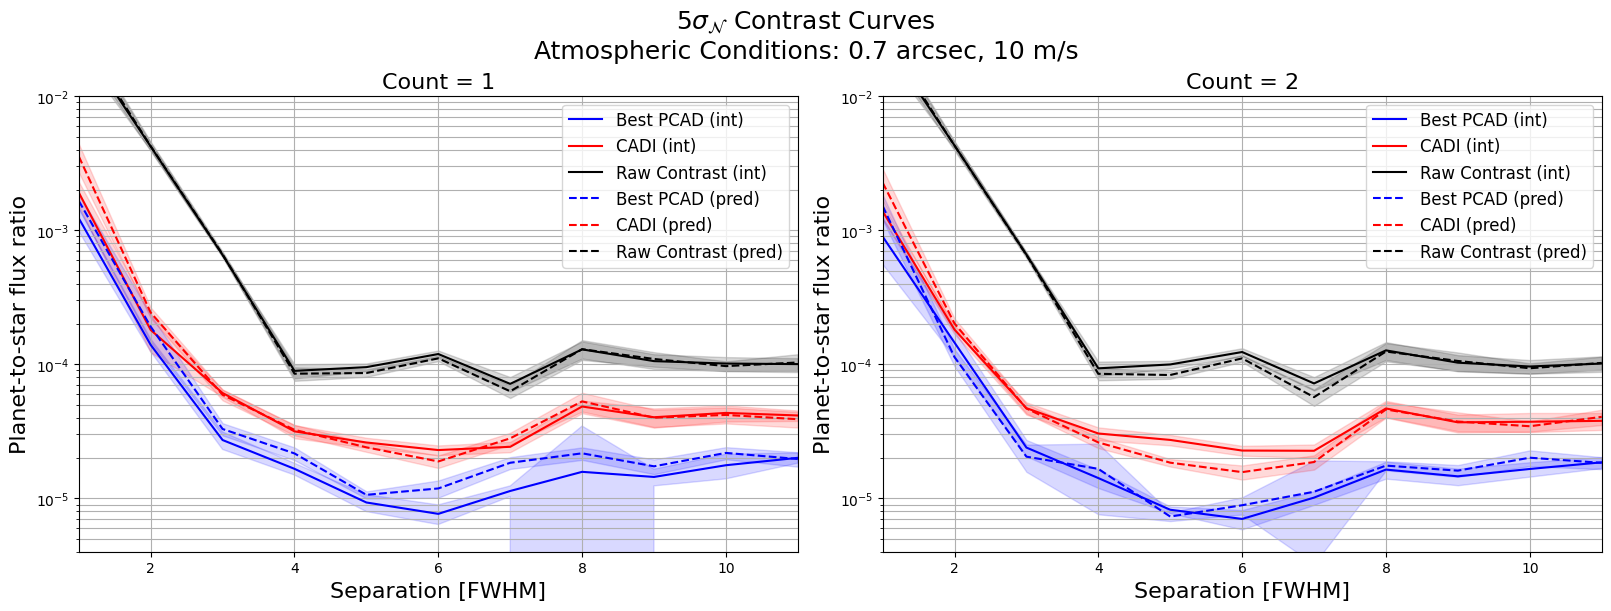

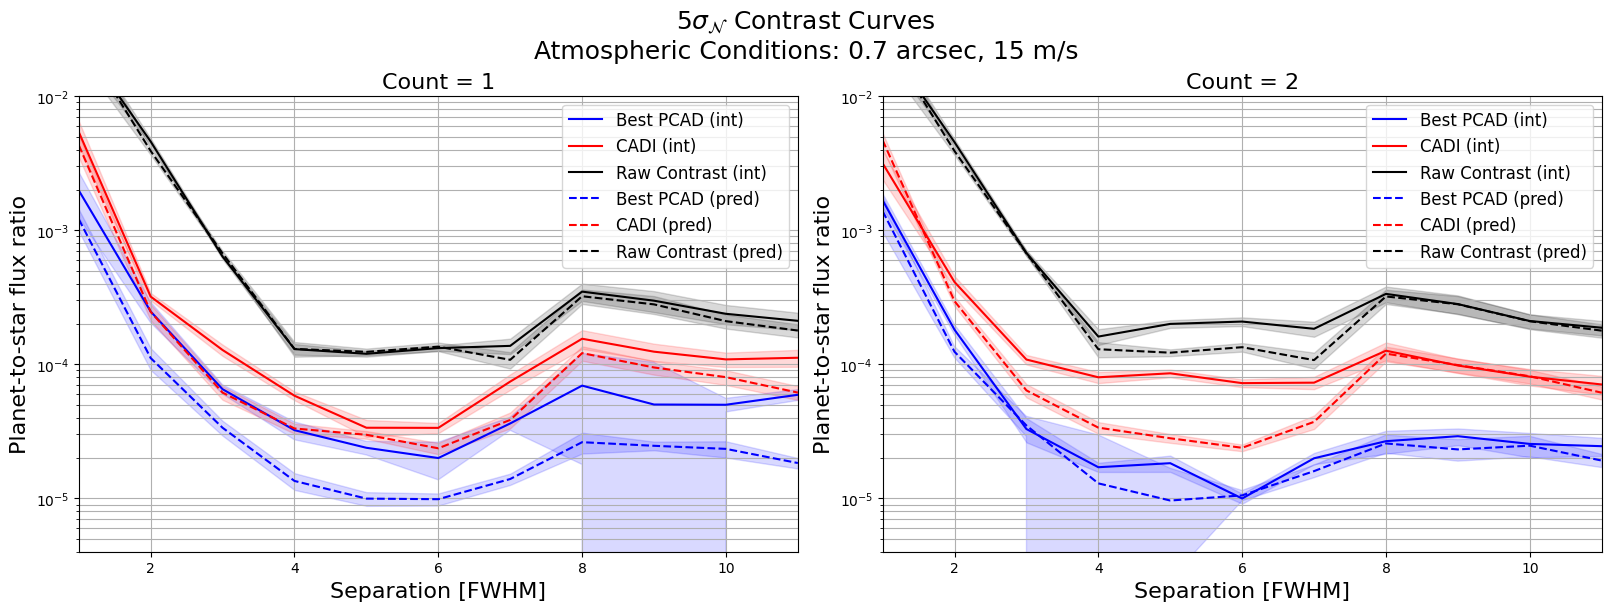

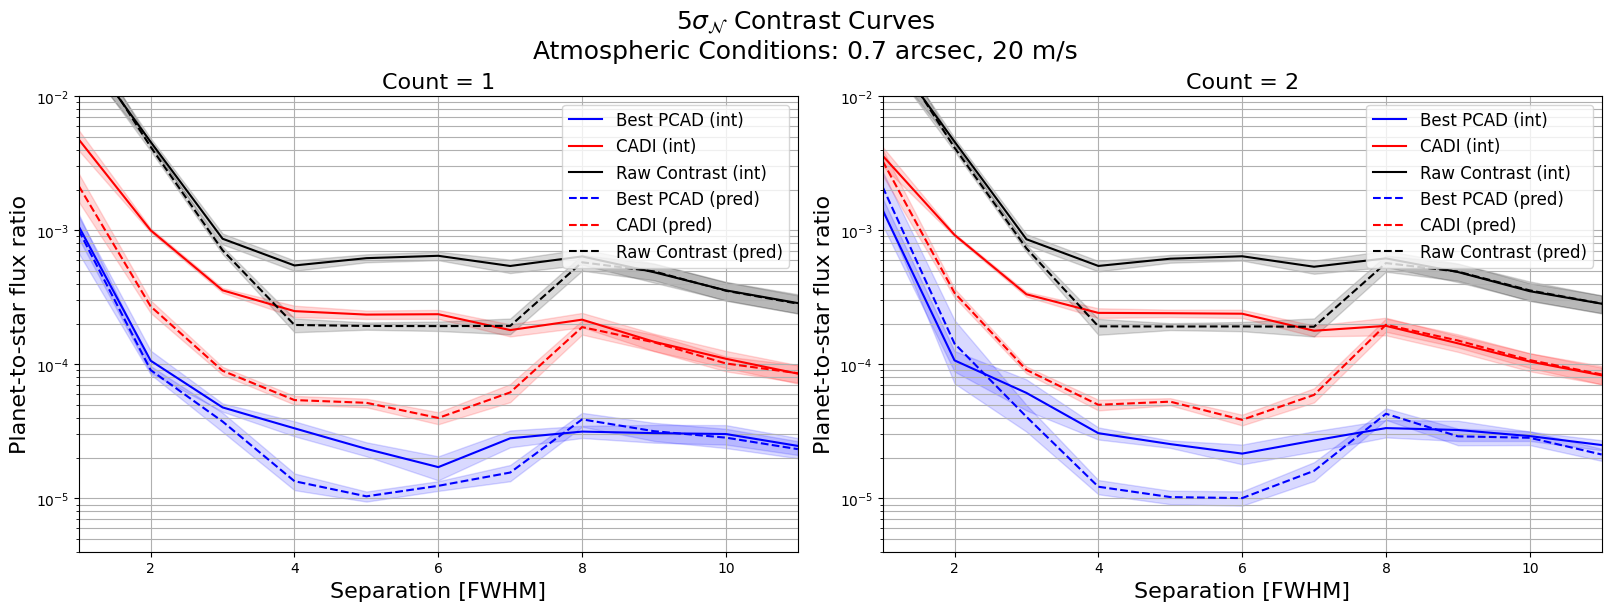

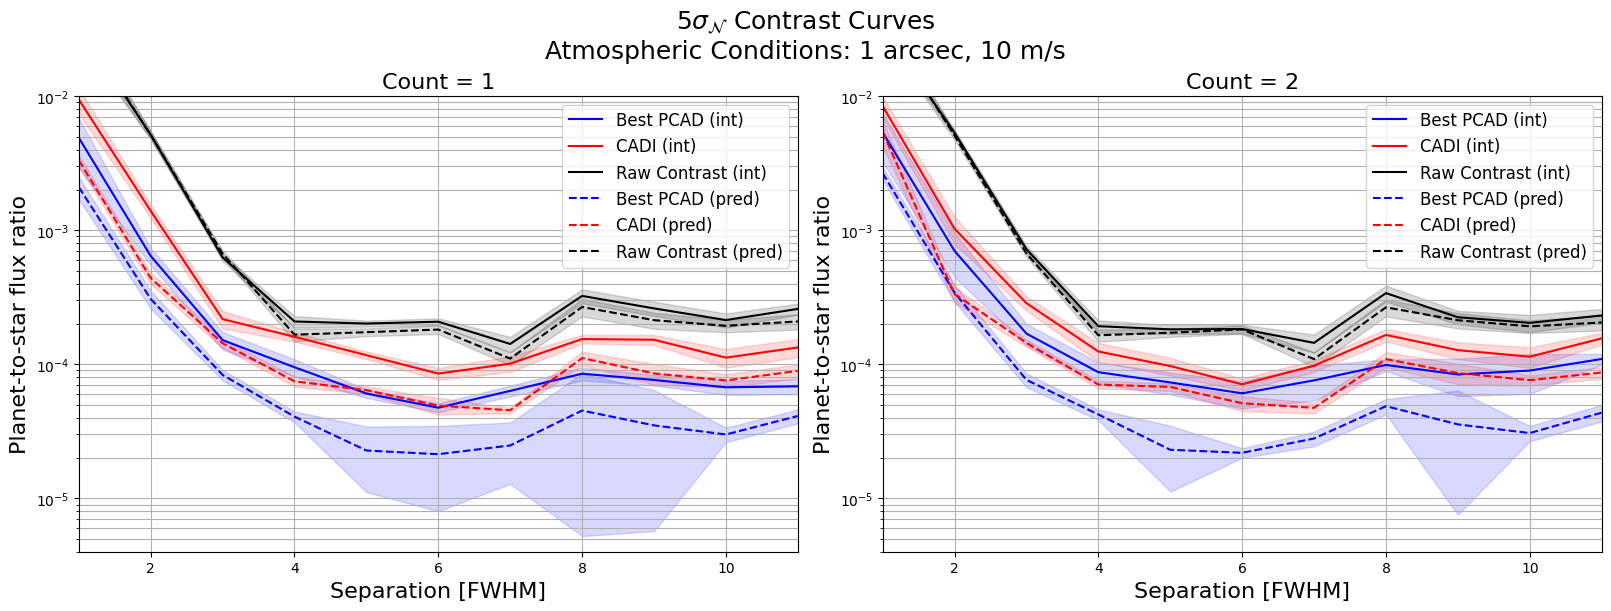

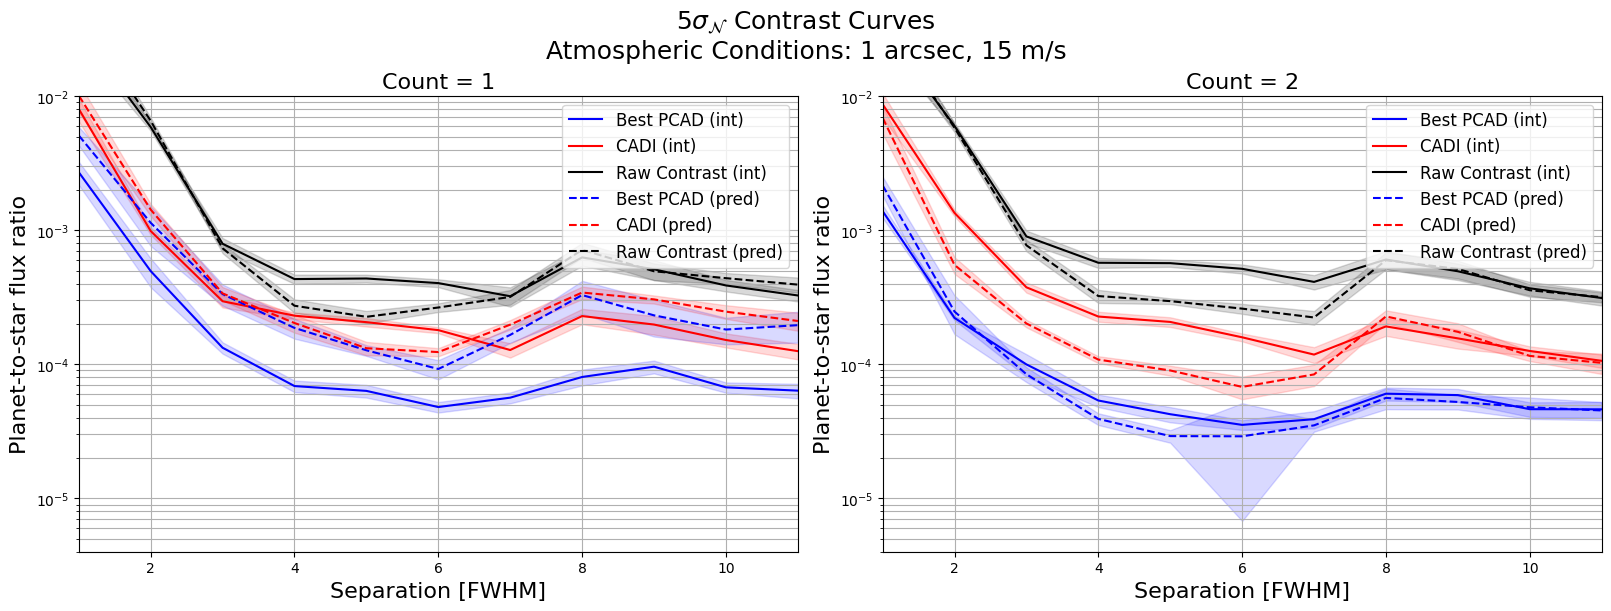

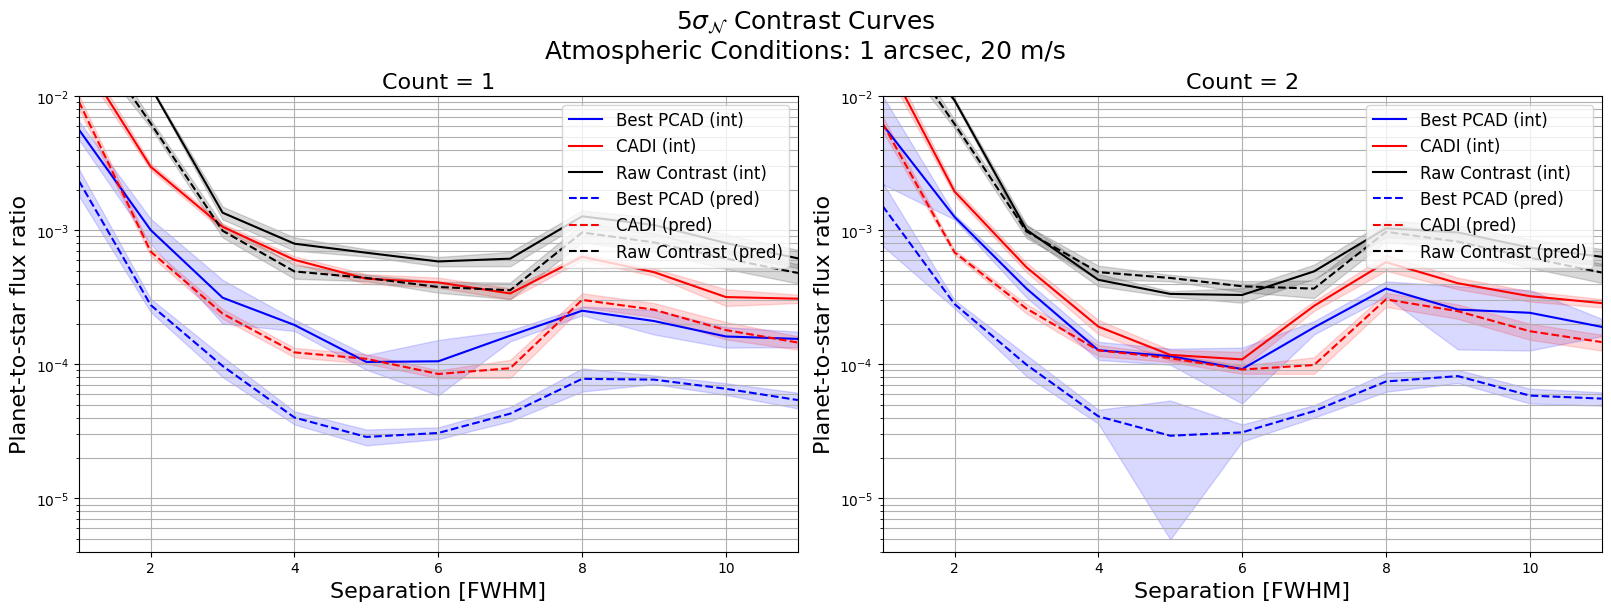

In [5]:
# PLOT BATCH 1 NEXT TO BATCH 2

plt.close('all')

for ro in [0.5, 0.7, 1.0]:
    for ws in [10, 15, 20]:

        name = f'{ro*10:.0f}ro_{ws}ws'

        plt.figure(figsize=(16, 6), constrained_layout=True)

        for count in [1, 2]:

            plt.subplot(1, 2, count)

            for algo, ls in [('int', '-'), ('pred', '--')]:

                full_name = f'/{algo}_{name}_{count}'

                df = all_best[full_name]

                x = df['best_contrast'].index.get_level_values('pixel_rad')

                rw = raw_contrast_dic[f'/{algo}_{name}_{count}']['raw_contrast']

                rwx = raw_contrast_dic[f'/{algo}_{name}_{count}']['raw_contrast'].index.get_level_values(
                    'pixel_rad'
                ) /4.8

                # Best PCAD
                plt.plot(
                    x,
                    df['best_contrast'],
                    color='blue',
                    ls=ls,
                    label=f'Best PCAD ({algo})'
                )

                # cADI
                plt.plot(
                    x,
                    df['cADI_contrast'],
                    color='red',
                    ls=ls,
                    label=f'CADI ({algo})'
                )

                # Raw contrast
                plt.plot(
                    x,
                    df['raw_contrast'],
                    color='black',
                    ls=ls,
                    label=f'Raw Contrast ({algo})'
                )

                # Uncertainties
                plt.fill_between(
                    x,
                    df['best_contrast'] - df['best_contrast_std'],
                    df['best_contrast'] + df['best_contrast_std'],
                    color='blue',
                    alpha=0.15
                )

                plt.fill_between(
                    x,
                    df['cADI_contrast'] - df['cADI_contrast_std'],
                    df['cADI_contrast'] + df['cADI_contrast_std'],
                    color='red',
                    alpha=0.15
                )

                plt.fill_between(
                    x,
                    df['raw_contrast'] - df['raw_contrast_std'],
                    df['raw_contrast'] + df['raw_contrast_std'],
                    color='black',
                    alpha=0.15
                )

            plt.grid(which='both')
            plt.yscale('log')
            plt.ylabel(r"Planet-to-star flux ratio", size=16)
            plt.xlabel(r"Separation [FWHM]", size=16)
            plt.xlim(min(x), max(x))
            plt.ylim(4e-6, 1e-2)
            plt.legend(fontsize=12, loc = 'upper right')

            plt.title(f'Count = {count}', size=16)

        plt.suptitle(
            r"$5 \sigma_{\mathcal{N}}$ Contrast Curves"
            + f"\nAtmospheric Conditions: {titling(name)}",
            size=18
        )

        plt.show()


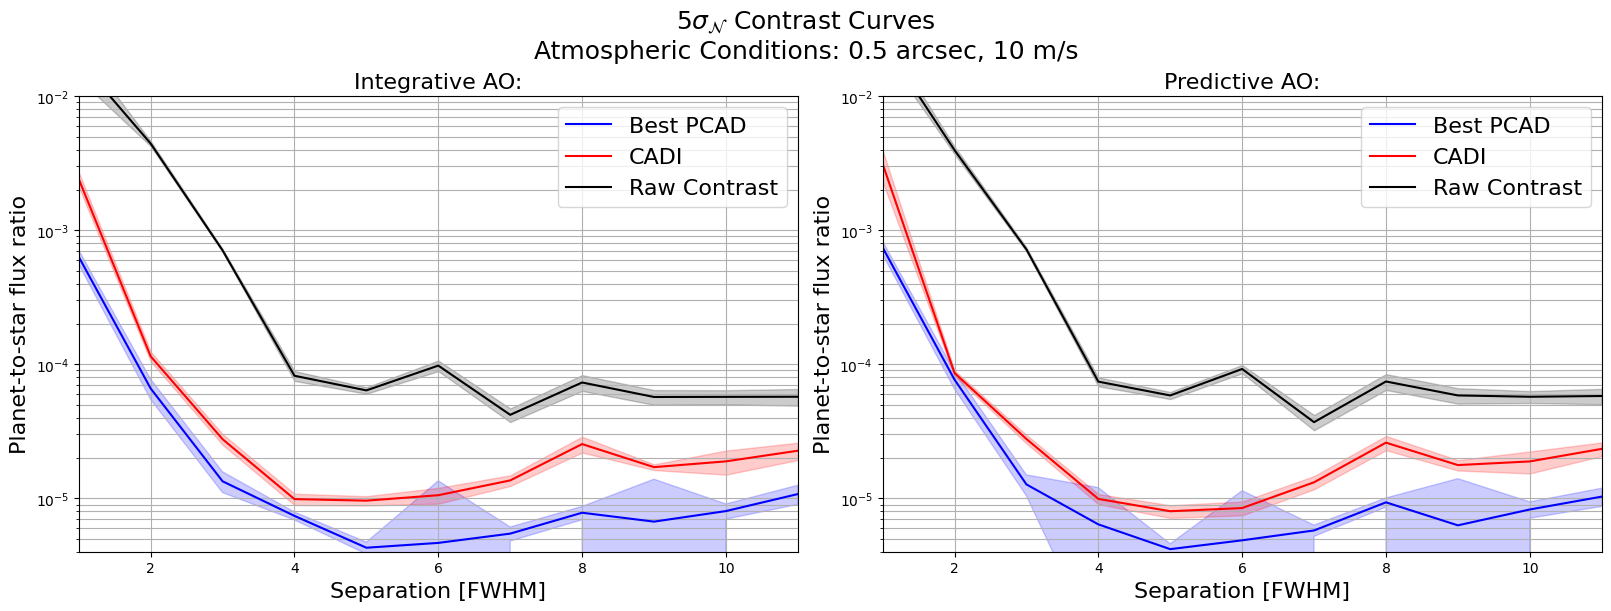

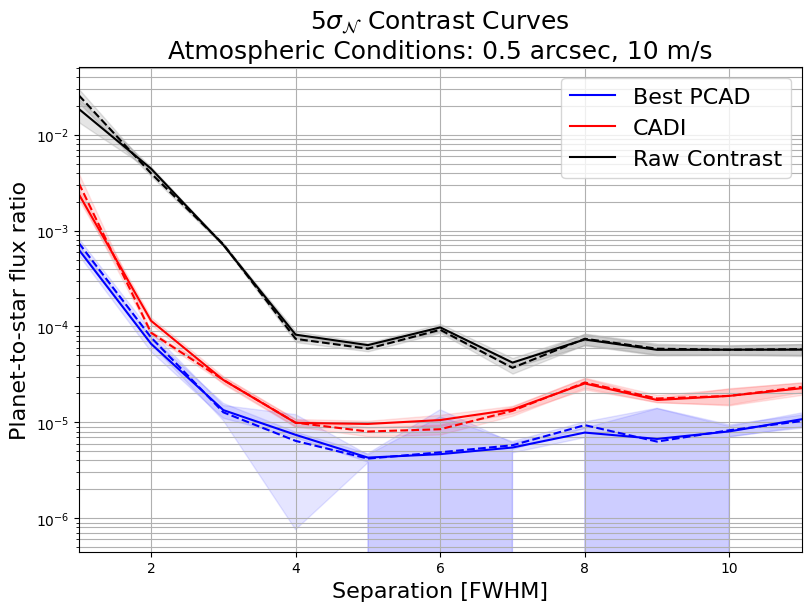

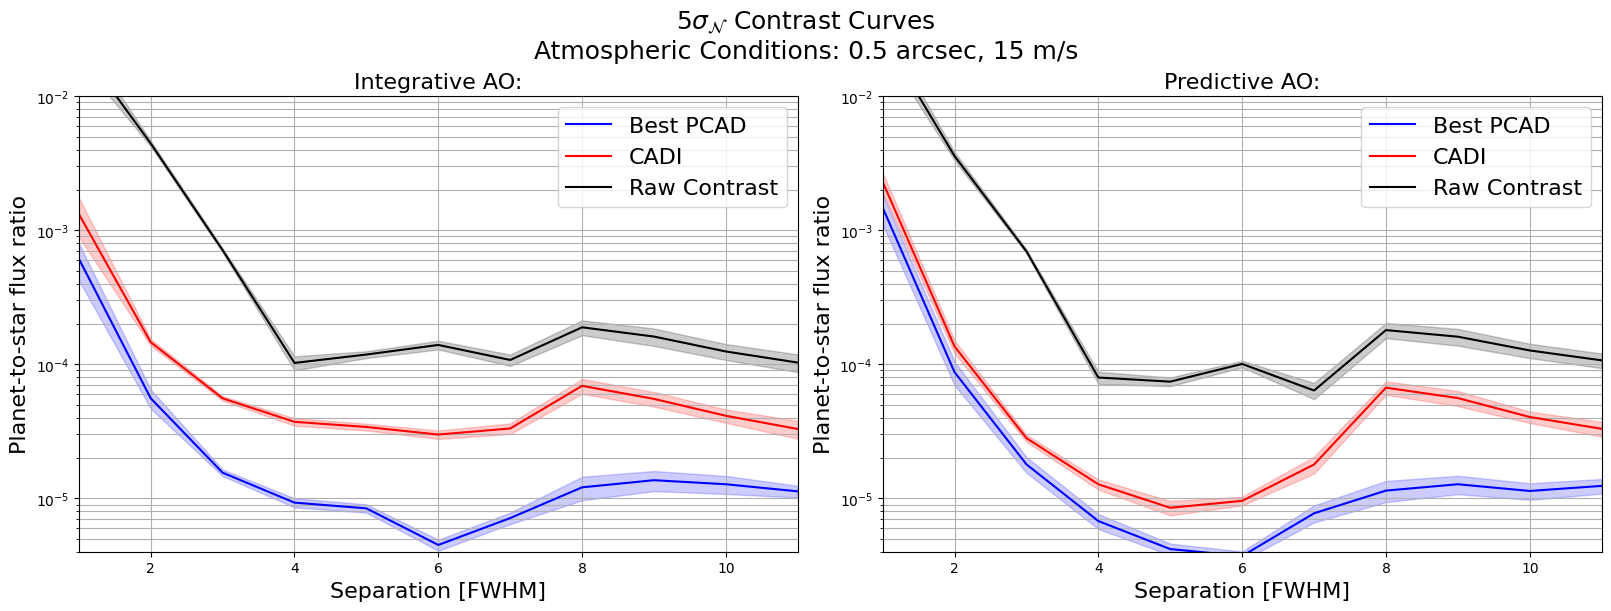

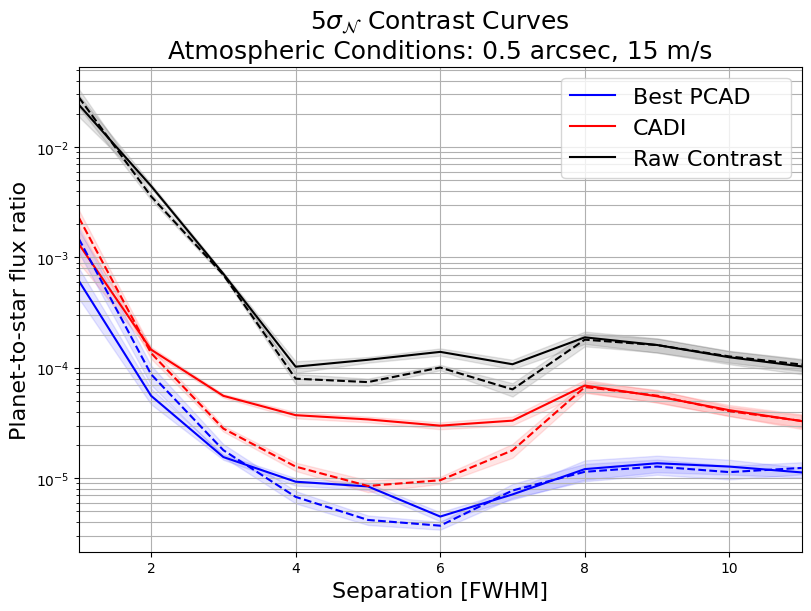

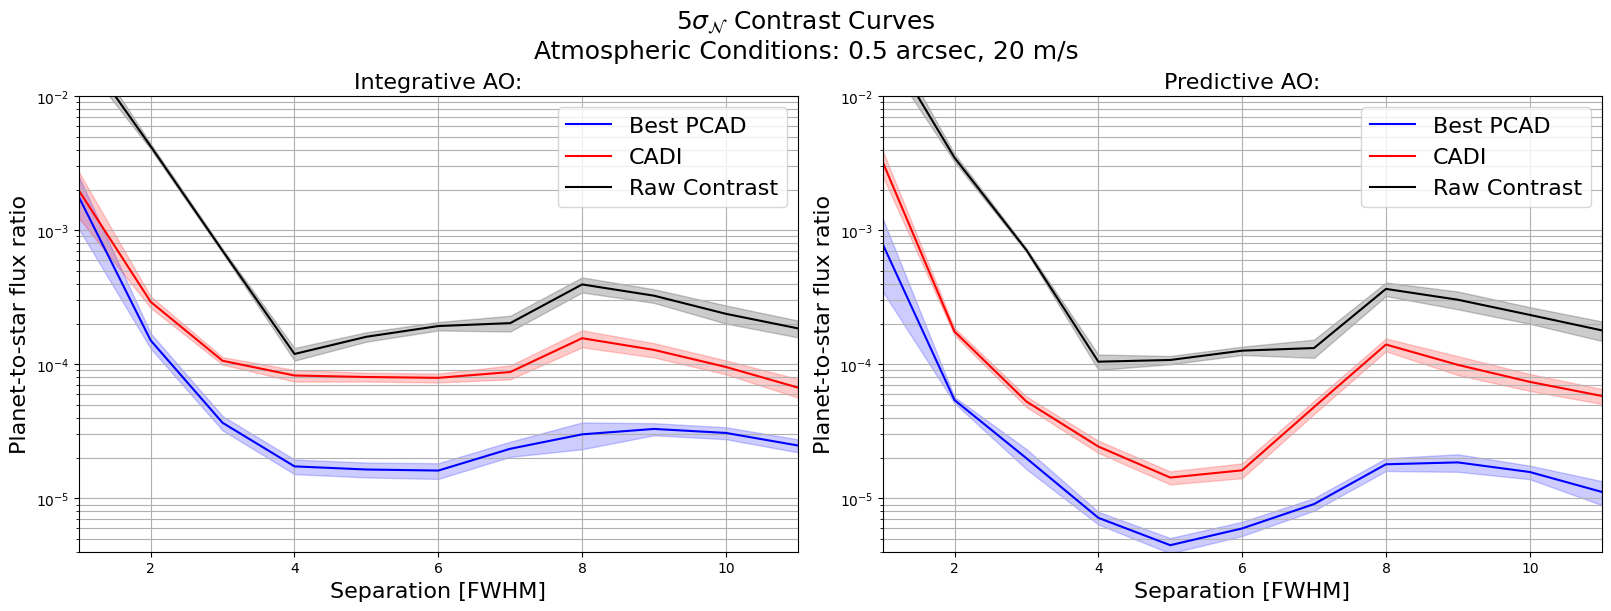

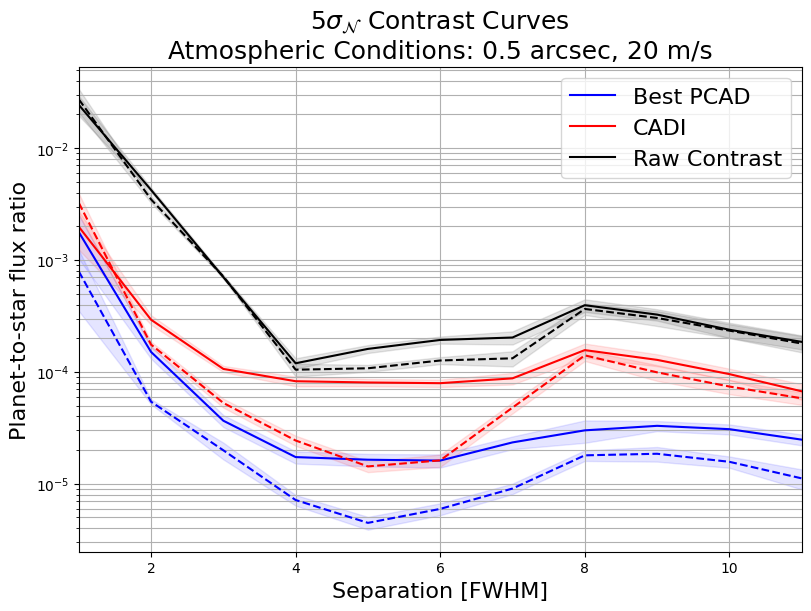

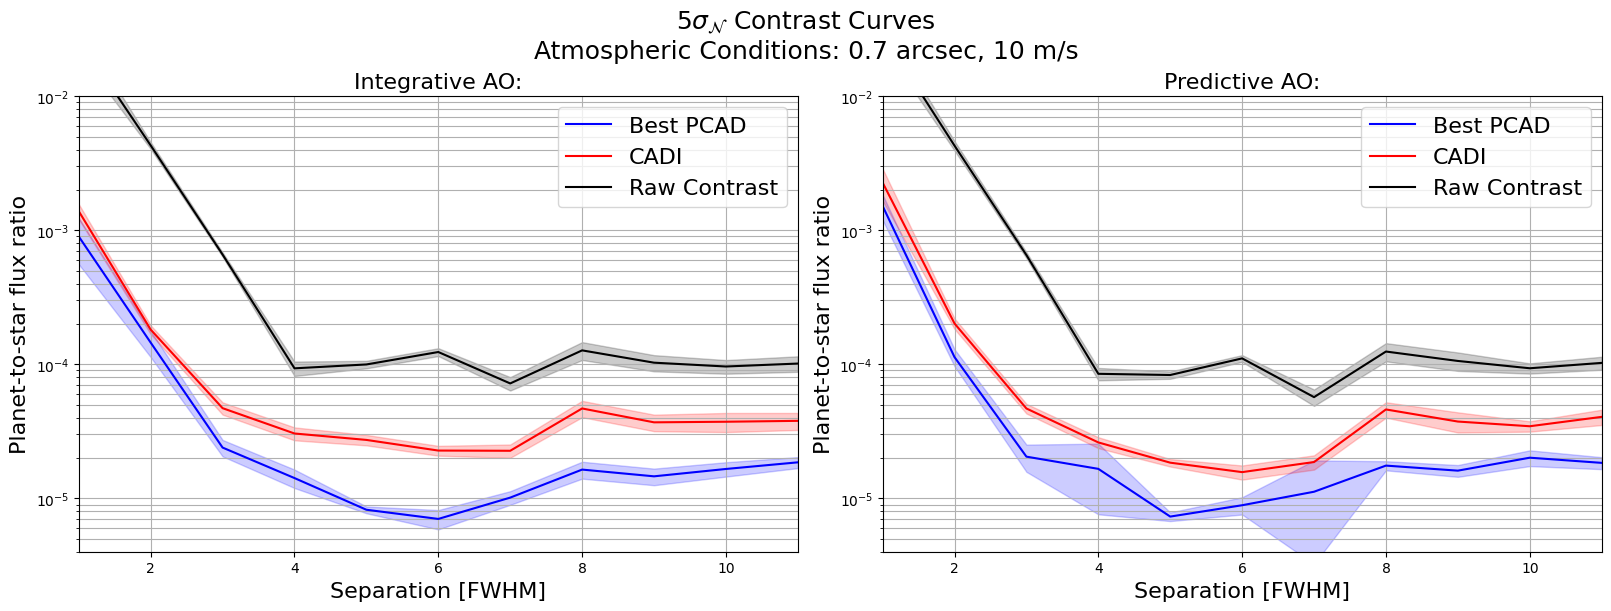

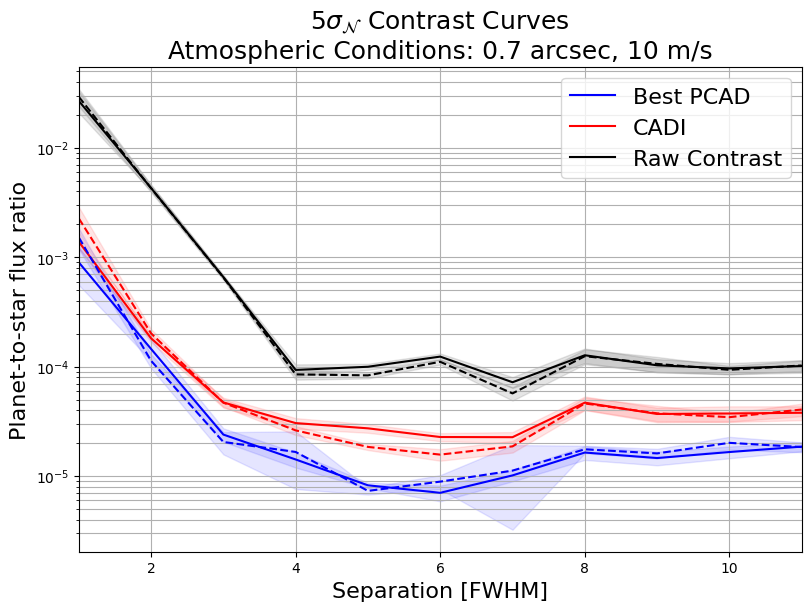

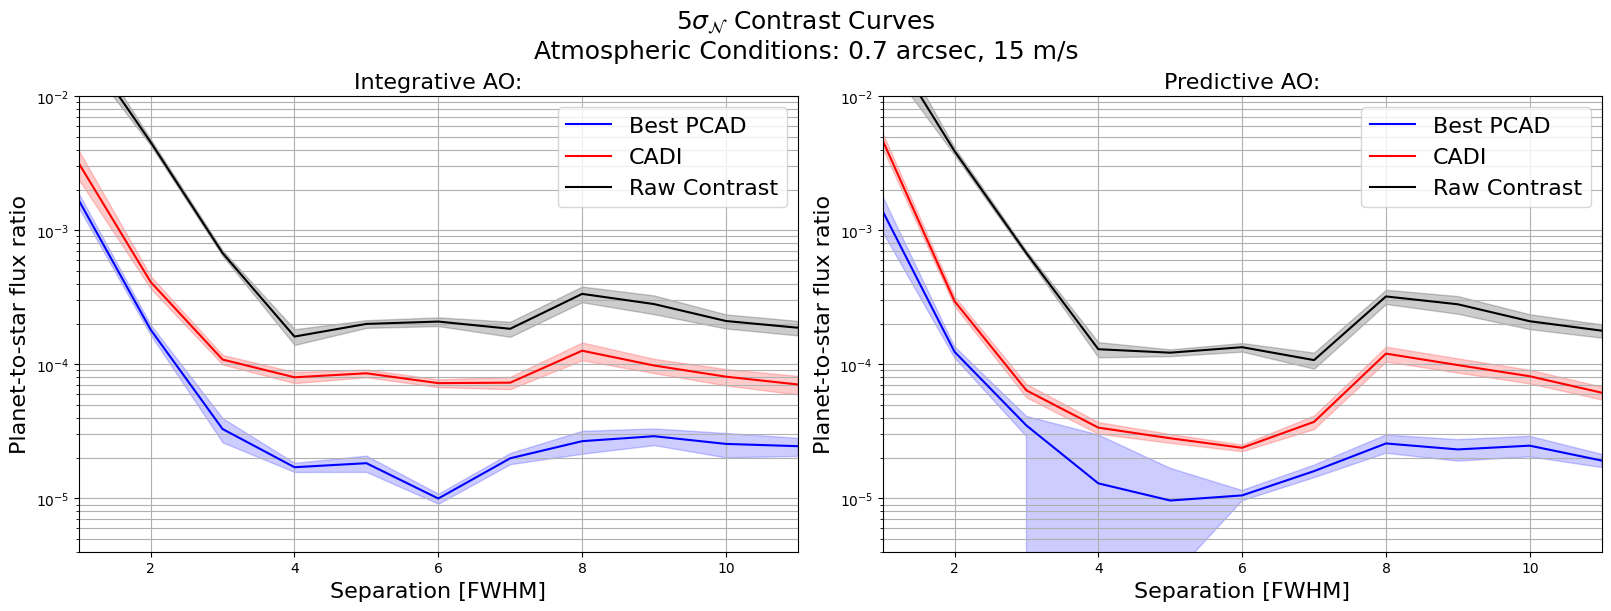

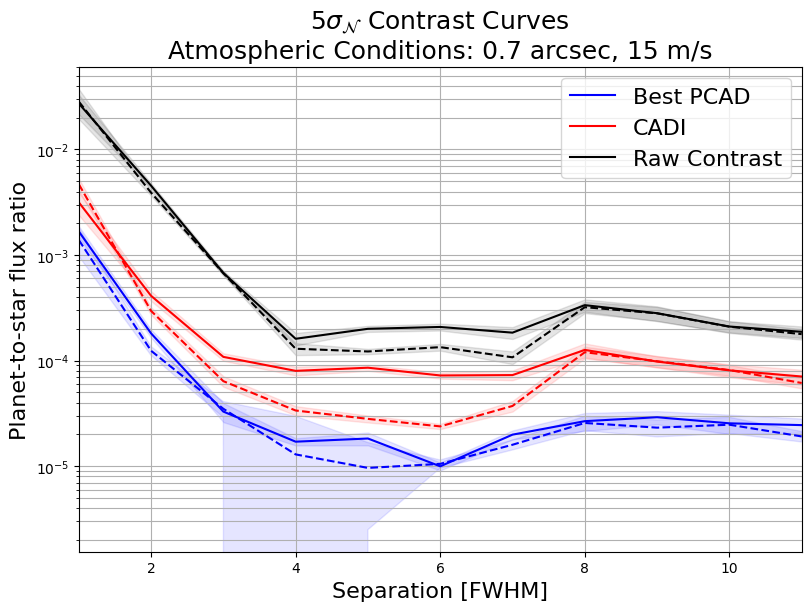

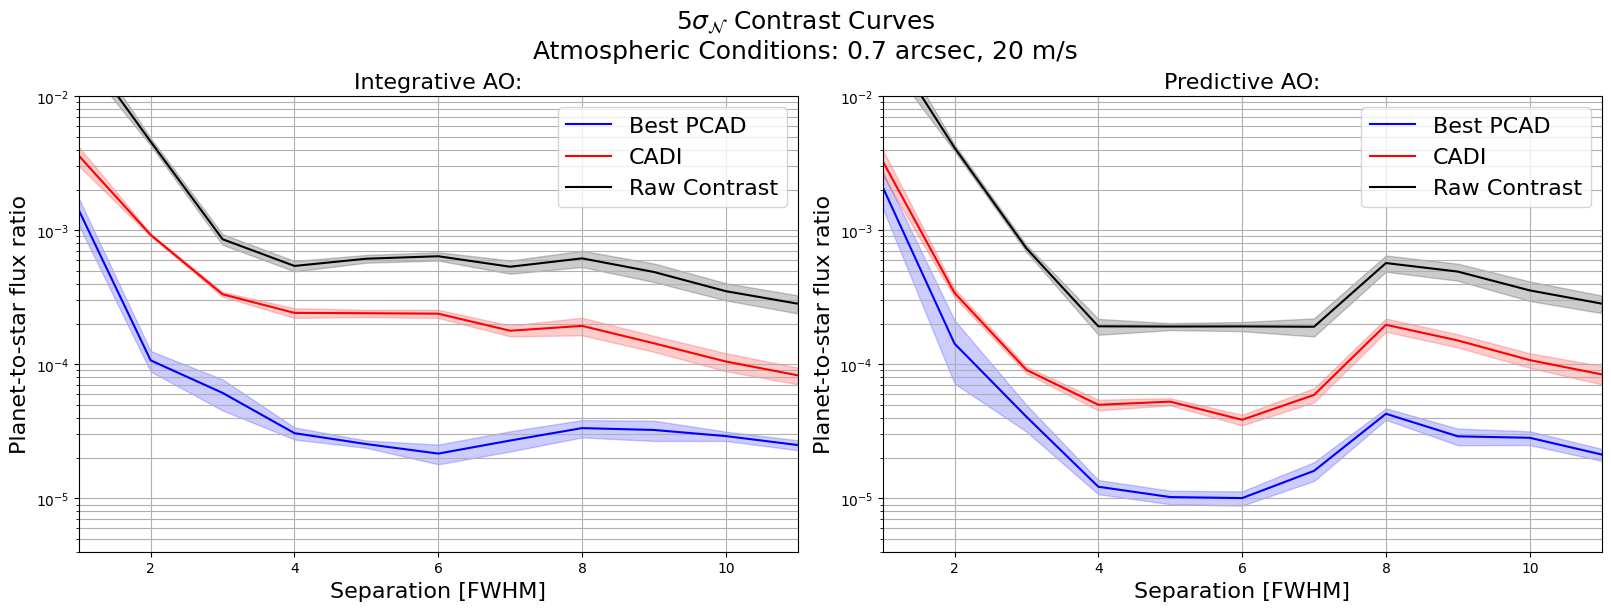

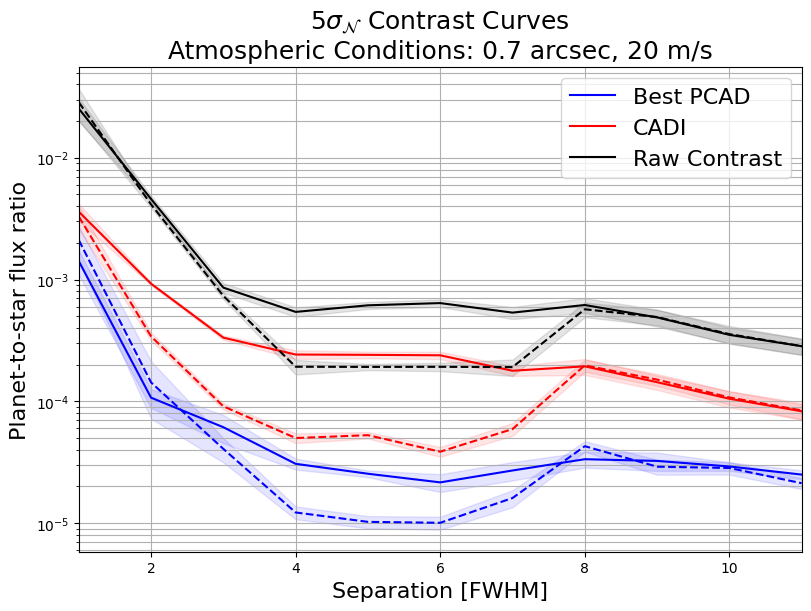

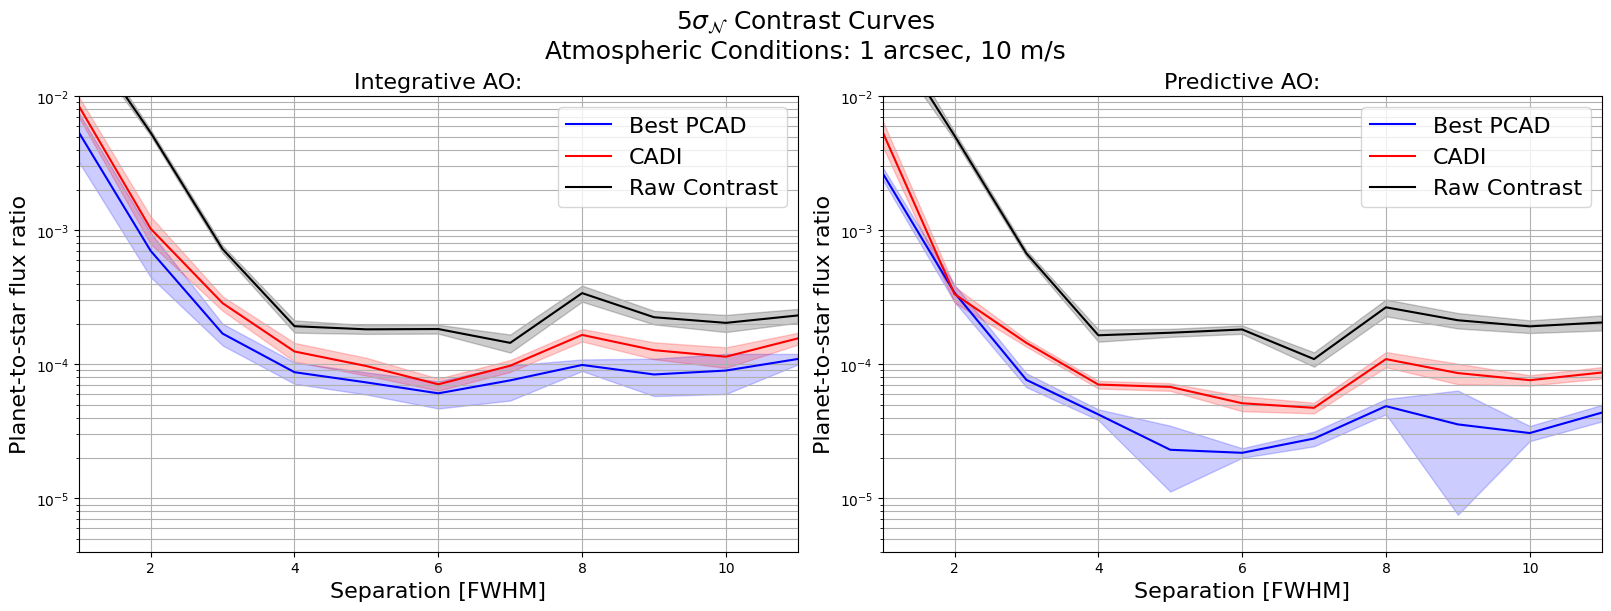

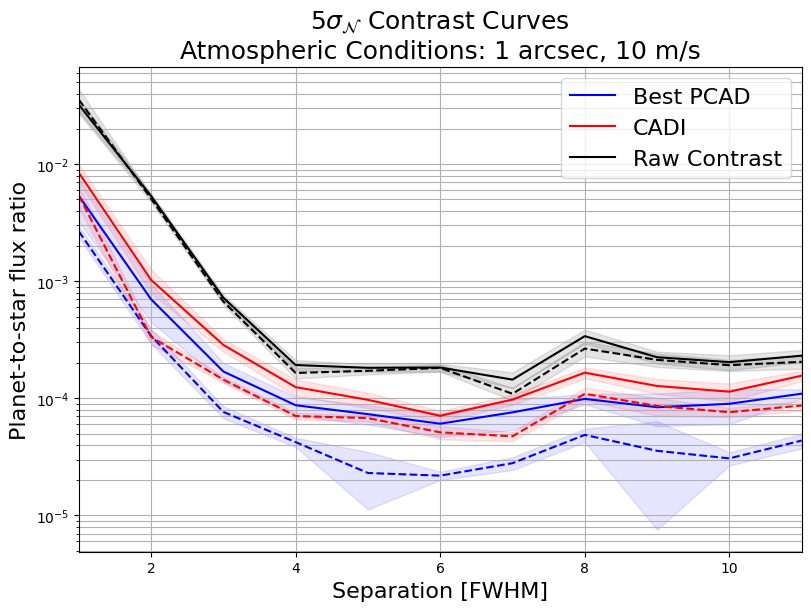

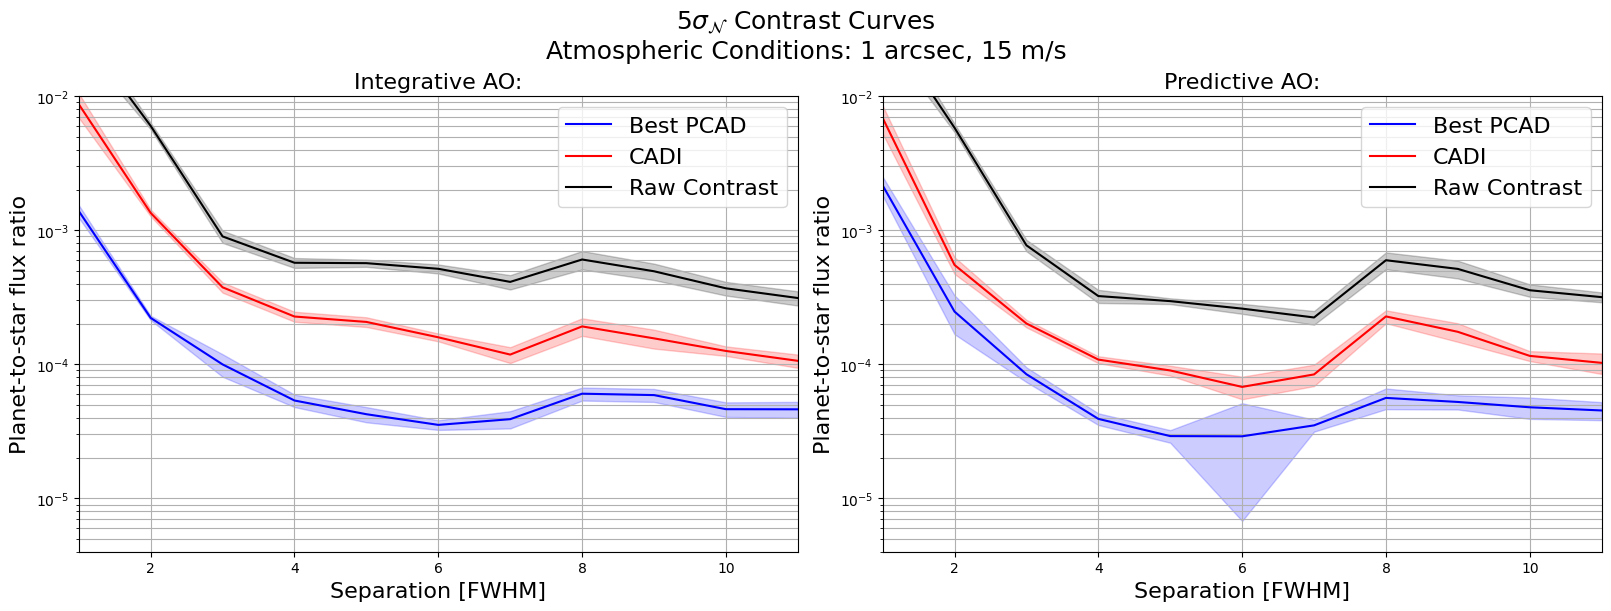

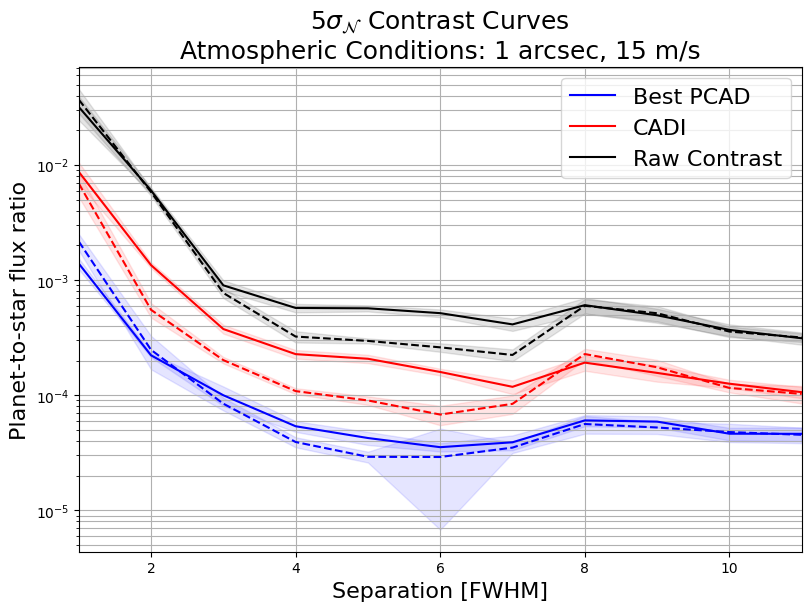

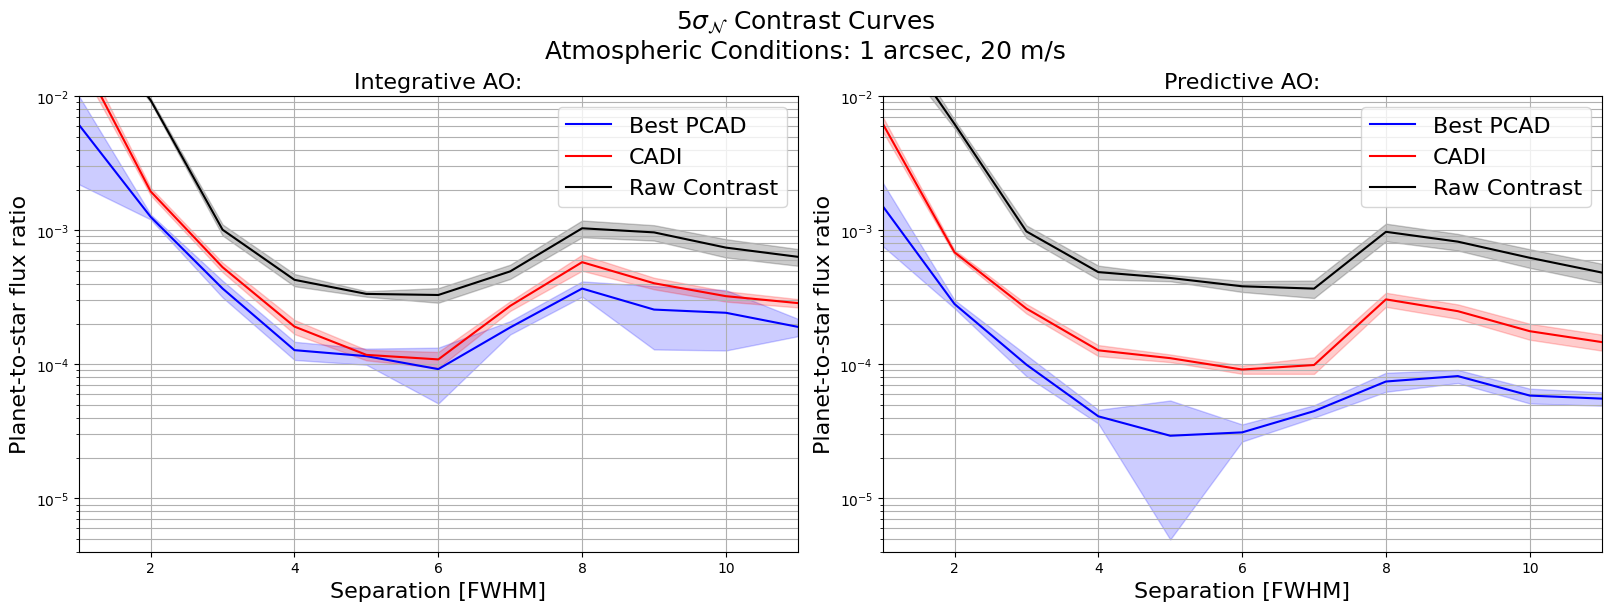

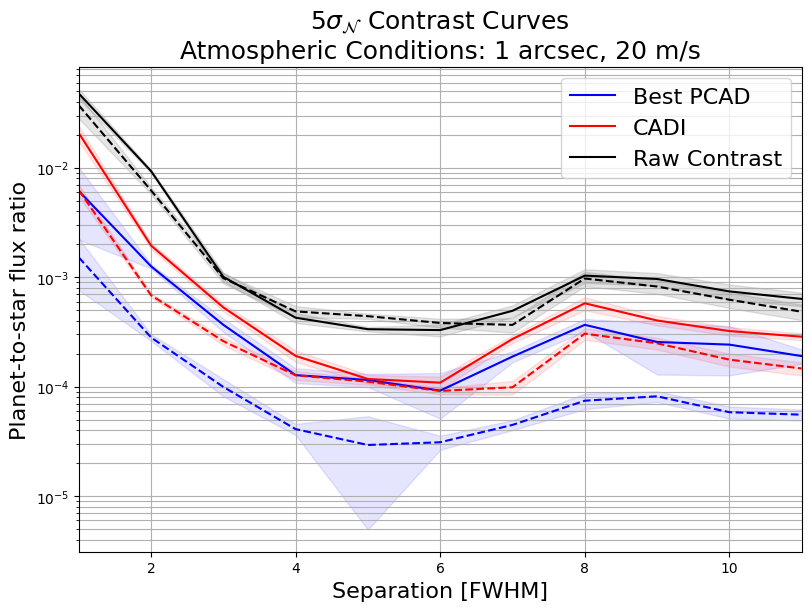

In [14]:
plt.close('all')

for ro in [0.5, 0.7, 1.0]:
    for ws in [10, 15, 20]:
            name = f'{ro*10:.0f}ro_{ws}ws'
            plt.figure(figsize = (16,6), constrained_layout = True)
            for algo in ['int', 'pred']:
                plt.subplot(1,2,1 if algo == 'int' else 2)
                full_name = f'{algo}_{name}'
                df = avr_best[full_name]
                x = df['best_contrast'].index.get_level_values('pixel_rad')
                x_rc = df['raw_contrast'].index.get_level_values('pixel_rad')
                plt.plot(x, df['best_contrast'], color = 'blue', label = 'Best PCAD')
                plt.plot(x, df['cADI_contrast'], color = 'red', label = 'CADI')
                plt.plot(x_rc, df['raw_contrast'], color = 'black', label = 'Raw Contrast')
                plt.fill_between(x, df['best_contrast'] - df['best_contrast_std'], df['best_contrast'] + df['best_contrast_std'], color = 'blue', alpha = 0.2)
                plt.fill_between(x, df['cADI_contrast'] - df['cADI_contrast_std'], df['cADI_contrast'] + df['cADI_contrast_std'], color = 'red', alpha = 0.2)
                plt.fill_between(x_rc, df['raw_contrast'] - df['raw_contrast_std'], df['raw_contrast'] + df['raw_contrast_std'], color = 'black', alpha = 0.2)
                         

                plt.grid( which= 'both')
                plt.yscale('log')
                plt.ylabel(r"Planet-to-star flux ratio", size=16)
                plt.xlabel(r"Separation [FWHM]", size=16)
                plt.xlim(min(x), max(x))
                plt.ylim(4e-6, 1e-2)
                plt.legend(fontsize = 16)
                plt.title(titling(algo), size=16)
            
            plt.suptitle(r"$5 \sigma_{\mathcal{N}}$ Contrast Curves" + f"\nAtmospheric Conditions: {titling(name)}", size=18)

            plt.figure(figsize = (8,6), constrained_layout = True)
            for algo in ['int', 'pred']:
                ls = '-' if algo == 'int' else '--'
                full_name = f'{algo}_{name}'
                df = avr_best[full_name]
                x = df['best_contrast'].index.get_level_values('pixel_rad')
                x_rc = df['raw_contrast'].index.get_level_values('pixel_rad')
                plt.plot(x, 
                         df['best_contrast'], 
                         color = 'blue', 
                         label = 'Best PCAD' if algo == 'int' else None, 
                         ls = ls)
                plt.plot(x, df['cADI_contrast'], color = 'red', label = 'CADI' if algo == 'int' else None, 
                         ls = ls)
                plt.plot(x_rc, df['raw_contrast'], color = 'black', label = 'Raw Contrast'if algo == 'int' else None, 
                          ls = ls)
                plt.fill_between(x, df['best_contrast'] - df['best_contrast_std'], df['best_contrast'] + df['best_contrast_std'], color = 'blue', alpha = 0.1)
                plt.fill_between(x, df['cADI_contrast'] - df['cADI_contrast_std'], df['cADI_contrast'] + df['cADI_contrast_std'], color = 'red', alpha = 0.1)
                plt.fill_between(x_rc, df['raw_contrast'] - df['raw_contrast_std'], df['raw_contrast'] + df['raw_contrast_std'], color = 'black', alpha = 0.1)
                            

            plt.grid( which= 'both')
            plt.yscale('log')
            plt.ylabel(r"Planet-to-star flux ratio", size=16)
            plt.xlabel(r"Separation [FWHM]", size=16)
            plt.xlim(min(x), max(x))
            #plt.ylim(4e-6, 1e-2)
            plt.legend(fontsize = 16)
            plt.title(r"$5 \sigma_{\mathcal{N}}$ Contrast Curves" + f"\nAtmospheric Conditions: {titling(name)}", size=18)
            



# Post Processing Gains

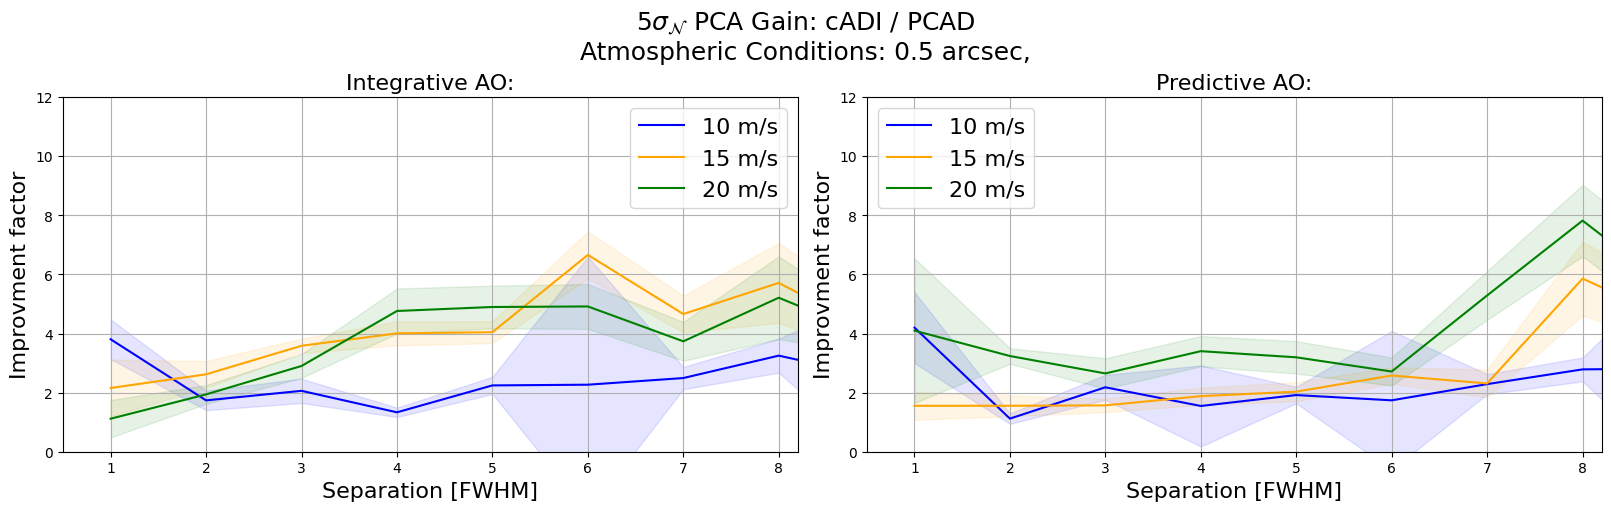

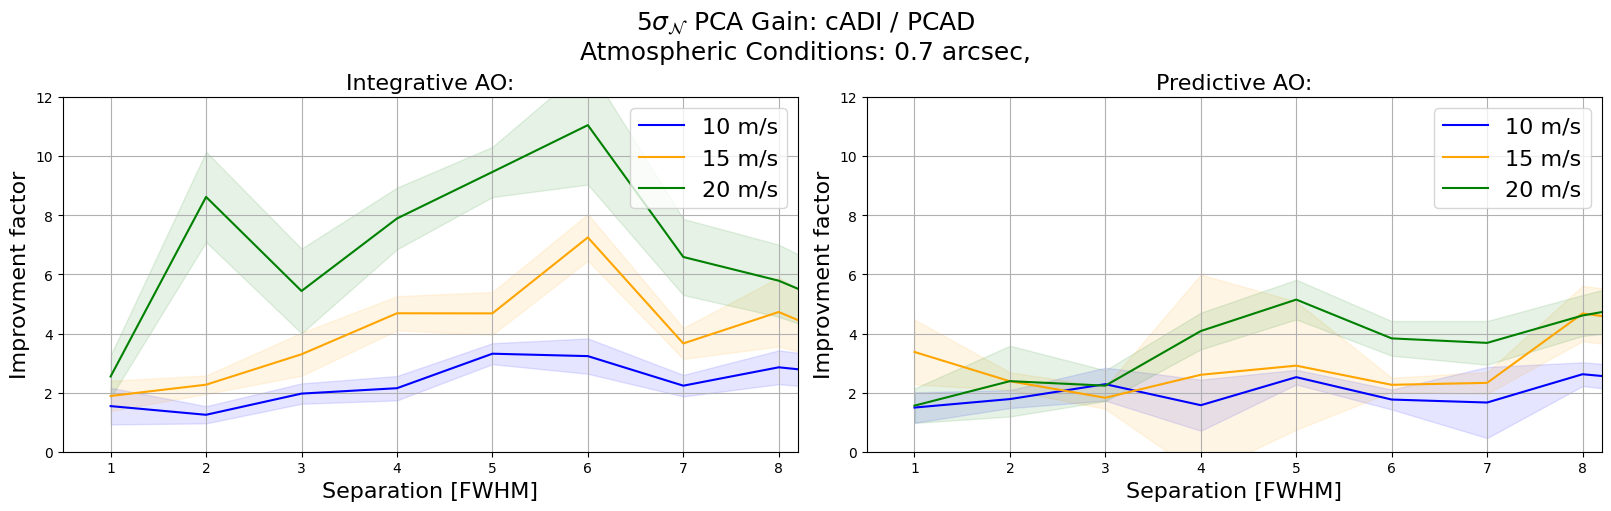

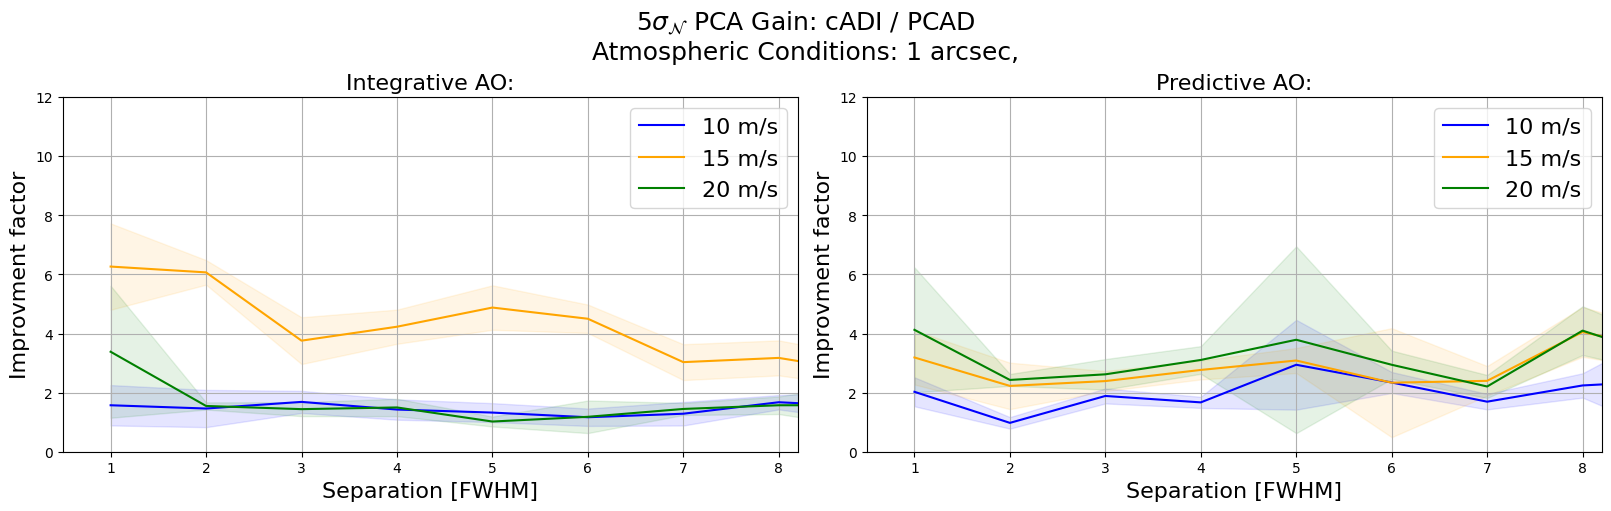

In [16]:
colours = {
    10: 'blue',
    15: 'orange',
    20: 'green'
}


plt.close('all')

for ro in [0.5, 0.7, 1.0]:

    plt.figure(figsize = (16,5), constrained_layout = True)

    for algo in ['int', 'pred']:

        plt.subplot(1,2,1 if algo == 'int' else 2)

        for ws in [10, 15, 20]:

                name = f'{ro*10:.0f}ro'

                full_name = f'{algo}_{name}_{ws}ws'

                df = avr_best[full_name]
                df = all_best[full_name + '_2']

                x = df['best_contrast'].index.get_level_values('pixel_rad')

                # PCA gain: cADI - PCAD
                gain = df['cADI_contrast'] / df['best_contrast']

                # Propagated uncertainty
                gain_std = (
                    (df['cADI_contrast_std'] / df['best_contrast'])**2
                    + (
                        df['cADI_contrast'] * df['best_contrast_std']
                        / df['best_contrast']**2
                    )**2
                )**0.5

                plt.plot(
                    x,
                    gain,
                    color = colours[ws],
                    label = f'{ws} m/s'
                )

                plt.fill_between(
                    x,
                    gain - gain_std,
                    gain + gain_std,
                    color = colours[ws],
                    alpha = 0.1
                )

                plt.grid(which = 'both')

                #plt.yscale('log')

                plt.ylabel(
                    r"Improvment factor",
                    size = 16
                )

                plt.xlabel(
                    r"Separation [FWHM]",
                    size = 16
                )

                plt.ylim(0, 12)
                plt.xlim(0.5, 8.2)

                plt.legend(fontsize = 16)

                plt.title(
                    titling(algo),
                    size = 16
                )

                plt.grid('both')

        plt.suptitle(
            r"$5 \sigma_{\mathcal{N}}$ PCA Gain: cADI / PCAD"
            + f"\nAtmospheric Conditions: {titling(name)}",
            size = 18
        )

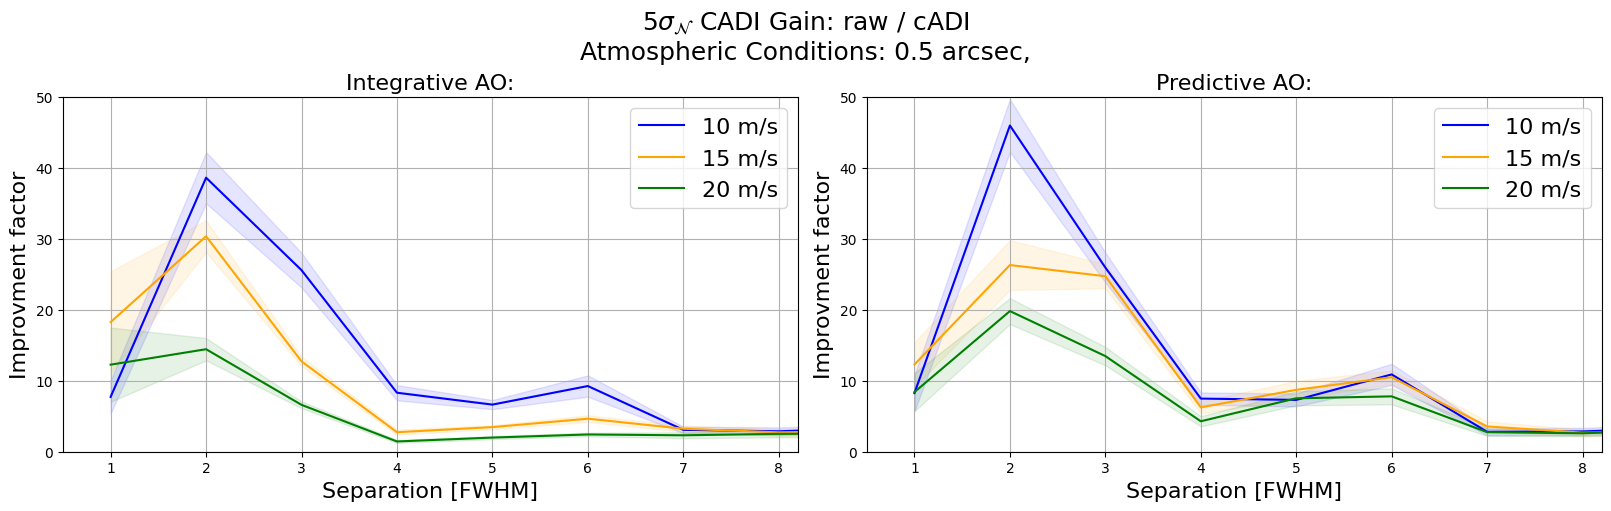

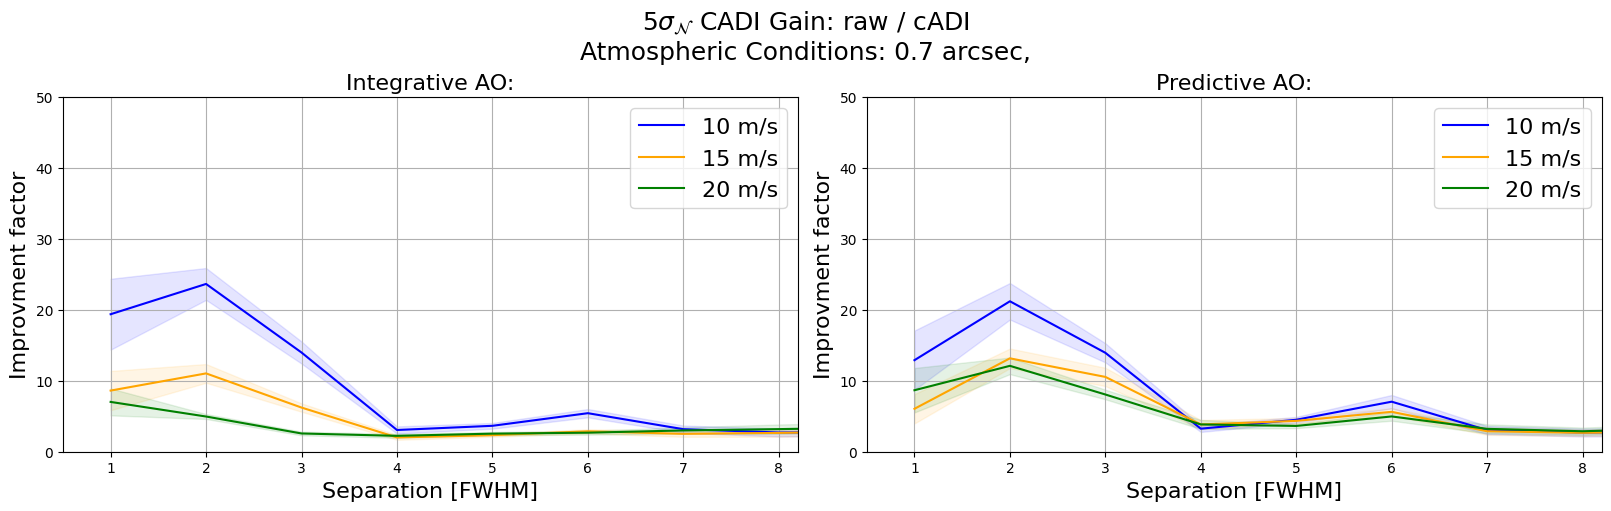

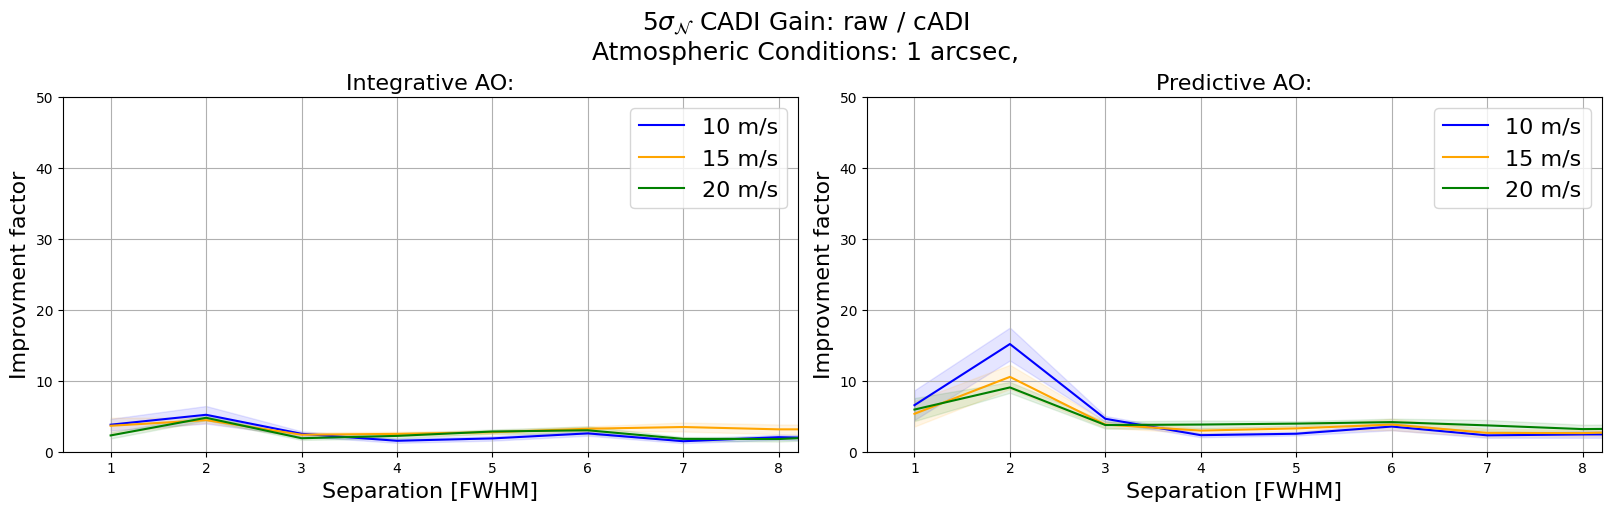

In [17]:
colours = {
    10: 'blue',
    15: 'orange',
    20: 'green'
}


plt.close('all')

for ro in [0.5, 0.7, 1.0]:

    plt.figure(figsize = (16,5), constrained_layout = True)

    for algo in ['int', 'pred']:

        plt.subplot(1,2,1 if algo == 'int' else 2)

        for ws in [10, 15, 20]:

                name = f'{ro*10:.0f}ro'

                full_name = f'{algo}_{name}_{ws}ws'

                df = avr_best[full_name]

                x = df['best_contrast'].index.get_level_values('pixel_rad')

                # PCA gain: cADI - PCAD
                gain = df['raw_contrast'] / df['cADI_contrast']

                # Propagated uncertainty
                gain_std = (
                    (df['raw_contrast_std'] / df['cADI_contrast'])**2
                    + (
                        df['raw_contrast'] * df['cADI_contrast_std']
                        / df['cADI_contrast']**2
                    )**2
                )**0.5

                plt.plot(
                    x,
                    gain,
                    color = colours[ws],
                    label = f'{ws} m/s'
                )

                plt.fill_between(
                    x,
                    gain - gain_std,
                    gain + gain_std,
                    color = colours[ws],
                    alpha = 0.1
                )

                plt.grid(which = 'both')

                #plt.yscale('log')

                plt.ylabel(
                    r"Improvment factor",
                    size = 16
                )

                plt.xlabel(
                    r"Separation [FWHM]",
                    size = 16
                )

                plt.ylim(0, 50)
                plt.xlim(0.5, 8.2)

                plt.legend(fontsize = 16)

                plt.title(
                    titling(algo),
                    size = 16
                )

                plt.grid('both')

        plt.suptitle(
            r"$5 \sigma_{\mathcal{N}}$ CADI Gain: raw / cADI"
            + f"\nAtmospheric Conditions: {titling(name)}",
            size = 18
        )

In [ ]:
plt.close('all')
for ro in [0.5, 0.7, 1.0]:
    plt.figure(figsize = (10,6))
    for ws in [20, 10]:
        name = f'coro_{ro*10:.0f}r0_{ws}windspeed'
        name = f'pred_{ro*10:.0f}ro_{ws}ws'
        df =  avr_best[name]
        #rw = raw_contrast[f'/pred_{ro*10:.0f}ro_{ws}ws_1']
        gain =  df['cADI_contrast'] - df['best_contrast']
        gain_std = (df['best_contrast_std']**2 + df['cADI_contrast_std']**2)**0.5
        plt.plot(x, gain, label = f'{ws} m/s')
        plt.fill_between(x, gain - gain_std, gain + gain_std, alpha = 0.2)
    plt.yscale('log')
    plt.title(r"PCA gain: cADI - PCAD" + f"\nAtmospheric Conditions: {ro} arcsec")
    plt.grid( which= 'both')
    plt.ylabel(r"Planet-to-star flux ratio", size=16)
    plt.xlabel(r"Separation [FWHM]", size=16)
    #plt.xlim(min(df['cADI_contrast'].index), max(df['cADI_contrast'].index))
    plt.legend()

In [55]:
all_best.close()
raw_contrast_dic.close()